# Chapter 7: Variational Quantum Algorithms for Many-Body Systems

*In this chapter we explore variational quantum algorithms as a practical approach for near-term devices. We explain the Variational Quantum Eigensolver (VQE): preparing a parametrized quantum state (ansatz), measuring its energy, and using a classical optimizer to minimize the expectation value. Common ansätze (hardware-efficient circuits, or problem-inspired ones like unitary coupled-cluster) are discussed, as well as measurement strategies for obtaining Hamiltonian expectation values. Practical issues such as noise, barren plateaus, and error mitigation strategies are addressed. We also mention related approaches such as the Quantum Approximate Optimization Algorithm (QAOA) and strategies for targeting excited states using variational subspace methods.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

Phase estimation, the subject of Chapter 6, returns an
eigenvalue to a precision that grows exponentially with the size of a
register, and it needs for that a coherent circuit whose depth grows in
the same proportion, together with a controlled version of $e^{-i\hat{H}t}$.
On the hardware of the present decade neither is available, and the
tables of that chapter were produced on a simulator whose state vector
never decohered. This chapter is about what can be done when the circuit
must be shallow, the gates are noisy, and the only operation that can be
repeated a million times is a short preparation followed by a
measurement. The answer is the oldest idea in many-body physics, the
variational principle of Chapter 3, run with a quantum
computer in the place where the trial state is evaluated: the
*variational quantum eigensolver*, VQE [Peruzzo2014,McClean2016].

The idea is simple enough to state in one sentence. A parametrized
circuit prepares a state $\vert\psi(\vec{\theta})\rangle$; the quantum
computer measures its energy $\langle\psi(\vec{\theta})\vert\hat{H}\vert\psi(\vec{\theta})\rangle$
one Pauli string at a time, exactly as in Section *Measuring a Pauli sum*;
a classical optimizer moves the parameters downhill; and the minimum is
an upper bound on the ground-state energy. Everything difficult about
the method is hidden in the words *circuit*, *measures* and
*optimizer*, and the chapter takes them in that order. The circuit,
the ansatz, decides what states are reachable at all, and the central
lesson of the calculations below is that the quality of a variational
result is a property of the ansatz rather than of the algorithm: a
circuit that knows nothing about the Hamiltonian can converge smoothly to
a wrong answer, and one that respects its symmetries can be exact with a
handful of parameters. The measurement decides the cost, which is
dominated not by the gates but by the number of repetitions needed to
beat down the statistical noise of the estimate, and there is a way of
reading the qubits that looks reasonable and produces a number that is
not the energy of any state. The optimizer needs gradients, which the
parameter-shift rule supplies exactly from two shifted energies when the
gate generators have two eigenvalues, and it must cope with a landscape
that flattens exponentially with the number of qubits when the circuit
is too generic.

The main business of the chapter is Sections *Two small Hamiltonians, worked through*
and *The model Hamiltonians*, where the algorithm is run on the same
Hamiltonians that Chapter 3 treated with configuration
interaction, Hartree--Fock and coupled cluster and Chapter 6
with phase estimation: the tapered one-qubit and the two-mode
Hamiltonians, then the Lipkin model, the pairing model, the Hubbard
ring and the Heisenberg ring of Table 6.6. The results are
set against the phase-estimation energies of Table 6.7,
and the two algorithms are weighed against each other. Section *Letting the algorithm choose the circuit: ADAPT-VQE*
then lets the algorithm choose its own circuit, one operator at a time
from a pool, which is the adaptive VQE, and finds the exact ground state
of the Heisenberg ring with a single operator once the right reference
and the right pool are supplied. Section *A second variational algorithm: QAOA* closes the
chapter with a second variational algorithm that is not about
Hamiltonians of physics at all: the quantum approximate optimization
algorithm, QAOA, which encodes a combinatorial problem in a diagonal
Hamiltonian and alternates it with a mixing term. It belongs here because
it is a VQE with a very particular ansatz, because its ansatz is the
Trotterized adiabatic evolution of Chapter 5, and
because it is the point of contact between the methods of this book and
quantum machine learning, of which we say a few words and no more. The
programs are in `BookPrograms/chapter7/`: the ansatz classes and
the VQE loop, the measurement and gradient checks, the model
calculations, an `AdaptVQE` class and a `QAOA` class. Every
number quoted below is printed by one of them.


## The variational principle on a circuit

The foundation is the inequality used by every approximate method of
Chapter 3. For a Hamiltonian $\hat{H}$ with
ground-state energy $E_0$ and any normalized state $\vert\psi\rangle$,

$$
E[\psi] = \langle\psi\vert\hat{H}\vert\psi\rangle \ge E_0 ,\tag{7.1}
$$

with equality if and only if $\vert\psi\rangle$ is a ground state. The
proof is one line in the eigenbasis: with
$\vert\psi\rangle=\sum_jc_j\vert\phi_j\rangle$ and
$\hat{H}\vert\phi_j\rangle=E_j\vert\phi_j\rangle$,

$$
\langle\psi\vert\hat{H}\vert\psi\rangle = \sum_j\vert c_j\vert^2E_j
 \ge E_0\sum_j\vert c_j\vert^2 = E_0 ,\tag{7.2}
$$

since every $E_j\ge E_0$ and the weights sum to one. Nothing about this
is quantum-computational; it is a statement about weighted averages.
What changes on a quantum computer is which states are available.
Restricting $\vert\psi\rangle$ to a family
$\vert\psi(\vec{\theta})\rangle$ labelled by real parameters turns
Eq. (7.1) into a minimization,

$$
E_{\mathrm{VQE}} = \min_{\vec{\theta}}
 \langle\psi(\vec{\theta})\vert\hat{H}\vert\psi(\vec{\theta})\rangle \ge E_0 ,\tag{7.3}
$$

and that is the whole algorithm. The family is generated by a
parametrized circuit acting on a reference state that is easy to
prepare,

$$
\vert\psi(\vec{\theta})\rangle = U(\vec{\theta})\,\vert\Phi_0\rangle ,\tag{7.4}
$$

so that the trial states are exactly those a quantum computer can
prepare in a few layers of gates. This is the point of the exercise. A
classical variational calculation is limited to states whose amplitudes
can be written down and summed over: the Hartree--Fock determinant of
Section *Hartree--Fock theory* is a product state in a rotated basis, and the
coupled-cluster wave function of Section *Coupled-cluster theory* is an
exponential whose evaluation had to be organized into the amplitude
equations of Section *The CCD equations* precisely because the
state itself cannot be stored. A circuit of depth $d$ on $n$ qubits
prepares a state with $2^n$ amplitudes, correlated in ways that no
compact classical parametrization reproduces, using $\bigO(nd)$
parameters, and its energy is obtained without ever writing the
amplitudes down. The hope of VQE rests on the belief that such states
are useful trial functions for physical Hamiltonians. The belief is
plausible, and largely unproven.

Two remarks about Eq. (7.3) are worth making at once,
because the whole chapter turns on them. The first is what the bound is
worth. It says that the answer lies above $E_0$; it does not say that it
lies close. If the family contains nothing near the ground state, the
optimizer converges beautifully to a number that is simply too high, and
its convergence tells us nothing about the quality of the answer. This
is the difficulty of every variational method in this book, since a
Hartree--Fock calculation also converges and also converges to the wrong
energy, and the remedies are the same: enlarge the family and watch
whether the number moves, compare families of different structure, and
check against exact results wherever the system is small enough to allow
it. The second is what the bound gives for free. Two variational numbers
can be compared, and the lower one is the better one, with no knowledge
of the exact answer. Phase estimation offers nothing of the kind:
Table 6.5 contains an estimate *below* the true
ground-state energy, which is a perfectly normal QPE result and one that
no variational calculation could ever produce.

*The loop.* As executed, the algorithm is the following.

1. Choose an ansatz $U(\vec{\theta})$, a reference $\vert\Phi_0\rangle$
   and initial parameters $\vec{\theta}^{(0)}$.
2. On the quantum device, prepare $\vert\psi(\vec{\theta})\rangle$
   and measure enough Pauli strings, enough times, to reconstruct
   $E(\vec{\theta})=\langle\psi(\vec{\theta})\vert\hat{H}\vert\psi(\vec{\theta})\rangle$.
3. On the classical device, use $E$ and, if available, its gradient
   to propose $\vec{\theta}^{(k+1)}$.
4. Repeat until the energy stops decreasing.

Steps 2 and 3 alternate hundreds or thousands of times, and Fig. 7.1
draws the division of labour. Step 2 is where the quantum computer earns
its place and where almost all of the cost lies; the classical side does
what any optimizer does. Most of this chapter is about how much step 2
costs, how it can go wrong, and how the ansatz of step 1 decides whether
the loop is worth running at all.

![The hybrid loop. The quantum device does one thing, the preparation an](../../BookFigures/chapter7/7-loop.png)

*Figure 7.1: The hybrid loop. The quantum device does one thing, the preparation and measurement of $\vert\psi(\vec{\theta})\rangle$, and does it many times per iteration; the classical device assembles the energy from the string expectation values and proposes the next parameters.*

The reader has met this loop twice already. Section *A first Hamiltonian: the two-level system*
minimized the energy of a two-level system over the Bloch angles of a
one-qubit state, Eq. (2.106), and
Section *A first variational circuit: unitary coupled cluster for the pairing model* minimized the seventeen-string pairing
Hamiltonian over the four angles of the pair-excitation circuit of
Eq. (4.25), reproducing the unitary coupled-cluster
energies of Table 3.15 digit for digit. Both were VQE
calculations with the expectation value taken exactly on the simulator.
What this chapter adds is the general machinery, the ansätze that are
not tied to one model, the statistics of the readout and the gradients,
and the systematic application to the models.


## The ansatz

The circuit $U(\vec{\theta})$ is built from parametrized rotations and
fixed entangling gates. The rotations are the exponentials of the Pauli
matrices of Eq. (2.96),

$$
R_x(\theta)=e^{-i\theta X/2},\qquad R_y(\theta)=e^{-i\theta Y/2},\qquad
R_z(\theta)=e^{-i\theta Z/2},\tag{7.5}
$$

and since $X^2=Y^2=Z^2=I$ each closes on two terms,
$R_a(\theta)=\cos(\theta/2)\,I-i\sin(\theta/2)\,\sigma_a$, Eq. (2.92).
The same is true of the Pauli rotations $e^{-i\theta P/2}$ of
Eq. (4.19) for any string $P$. This innocuous identity is
responsible for the parameter-shift rule of Section *Gradients on a quantum computer*:
because the exponential closes on two terms, the energy is a
trigonometric polynomial of degree one in each angle, and such a
polynomial can be differentiated exactly by evaluating it at two shifted
points.

### One qubit is a sphere

For a single qubit the general normalized state, up to a phase, is the
Bloch-sphere state of Eq. (2.35),
$\cos(\theta/2)\vert 0\rangle+e^{i\phi}\sin(\theta/2)\vert 1\rangle$, two
angles for two real degrees of freedom. A product of two rotations,

$$
\vert\psi(\theta_1,\theta_2)\rangle = R_z(\theta_2)R_y(\theta_1)\vert 0\rangle ,\tag{7.6}
$$

reaches every one-qubit state, and for a Hamiltonian with real matrix
elements the single rotation $R_y(\theta)\vert 0\rangle$ already
suffices, since the ground state of a real symmetric matrix can be
chosen real. For a one-qubit Hamiltonian the ansatz is therefore
*exact*: the variational minimum is the true ground state, and any
error in the result is the optimizer's fault and nobody else's. This is
why Section *Two small Hamiltonians, worked through* begins there. It is also the last case in
which anything of the kind is true.

### The hardware-efficient ansatz

The workhorse of the near-term literature [Kandala2017] places a
pair of rotations on every qubit and follows them with a fixed layer of
entangling gates, repeating the pattern $L$ times,

$$
U(\vec{\theta}) = \left[\prod_{q=0}^{n-1}R_z(\theta^{z}_{Lq})R_y(\theta^{y}_{Lq})\right]
 \prod_{\ell=1}^{L-1}\left[U_{\mathrm{ent}}\prod_{q=0}^{n-1}R_z(\theta^{z}_{\ell q})R_y(\theta^{y}_{\ell q})\right] ,\tag{7.7}
$$

applied to $\vert 0\cdots0\rangle$ and read from right to left. With a
ladder of CNOT gates as $U_{\mathrm{ent}}$, control $q$ and target $q+1$
for $q=0,\dots,n-2$, this uses $2nL$ parameters and $(n-1)(L-1)$
two-qubit gates; Fig. 7.2 shows two layers on three qubits.
It is called hardware-efficient because it is built from whatever gates
the machine executes natively and respects whatever connectivity it has,
and the name is honest about its virtue and silent about its defect:
*nothing in it knows anything about the Hamiltonian*. It does not
conserve particle number, does not respect spin or any other symmetry,
and is not guaranteed to contain any state resembling the ground state.
It is a generic family that happens to be cheap.

![The hardware-efficient ansatz of Eq. 7.7 with  layers on three qubits ](../../BookFigures/chapter7/7-hea.png)

*Figure 7.2: The hardware-efficient ansatz of Eq. (7.7) with $L=2$ layers on three qubits: $R_y$ and $R_z$ on every qubit, a CNOT ladder, a second layer of rotations, and the readout. Twelve parameters and two CNOT gates; the last layer carries no ladder, since entangling gates just before a measurement of the energy could be absorbed into the measurement.*

Two consequences follow, and both appear in the calculations of
Section *The model Hamiltonians*. The optimization landscape has many local
minima, so that restarts from several random initializations are not a
refinement but a necessity, and all the hardware-efficient results below
are the best of four. And as $n$ and $L$ grow the landscape flattens: for
a sufficiently random circuit the gradient of the energy has zero mean
and a variance that decays exponentially with the number of qubits. This
is the *barren plateau* of Section *Barren plateaus*. A third
consequence is specific to many-body physics and is the one the tables
below make most vividly. The Hamiltonians of Chapter 4
act on a register that contains every particle number at once, and the
physical ground state is the lowest state of one sector. A circuit that
does not conserve the particle number is free to leave the sector, and
if the register has a lower eigenvalue elsewhere, as the pairing and
Hubbard Hamiltonians of Table 6.6 do, the optimizer will
find it, quite correctly, and report an energy that is not the energy of
the system one wanted.

### Ansätze that know the physics

The alternative is to build the circuit from the Hamiltonian. The
unitary coupled-cluster ansatz of Section *Unitary coupled cluster*,

$$
\vert\psi(\vec{t})\rangle = e^{\hat{T}(\vec{t})-\hat{T}^{\dagger}(\vec{t})}\vert\Phi_0\rangle ,\tag{7.8}
$$

starts from the reference determinant and applies particle-hole
excitations, so it conserves the particle number by construction, has
parameters that are recognizable amplitudes, and reduces to the
classical coupled-cluster result in the appropriate limit. Its circuit
form is the Trotterized product of Eq. (3.58), one
Pauli rotation per string of each excitation, and Section *A first variational circuit: unitary coupled cluster for the pairing model*
showed for the pairing model that the one-step product with
re-optimized amplitudes is exactly as good an ansatz as the full
exponential. Every circuit of this kind has the form

$$
\vert\psi(\vec{\theta})\rangle = \prod_{k=K}^{1}e^{-i\theta_kG_k}\,\vert\Phi_0\rangle ,\tag{7.9}
$$

with Hermitian generators $G_k$ that are sums of Pauli strings and a
reference that is a computational basis state or another easily prepared
state, the first generator acting first. The pair excitation of
Eq. (4.23) is $G=-\frac12(Y_iX_a-X_iY_a)$; the
fermionic single excitation of Eq. (4.20) is the
same with the Jordan--Wigner string in between; a double excitation
$a^{\dagger}_ra^{\dagger}_ta_qa_p-\mathrm{h.c.}$ is eight strings. The
class `PauliRotationAnsatz` in `vqe.py` implements
Eq. (7.9) for any list of generators, applying each
exponential through the spectral decomposition of its matrix, which is
exact and fast at the sizes of this book, and it can also emit the
circuit of Section *The exponential of a Pauli string* for generators whose strings
commute. The script checks that it reproduces the pair-excitation
circuit of Fig. 4.5 to machine precision.

A second physically motivated family uses the Hamiltonian itself as the
generator. The *Hamiltonian-variational ansatz* [Wecker2015]
splits $\hat{H}=\sum_g\hat{H}_g$ into groups of mutually commuting
strings, the same groups that Chapter 5 exponentiated
in a Trotter step, and alternates them with one angle per group and
layer,

$$
\vert\psi(\vec{\theta})\rangle = \prod_{\ell=1}^{L}\left[\prod_g e^{-i\theta_{\ell g}\hat{H}_g}\right]\vert\Phi_0\rangle .\tag{7.10}
$$

With all angles equal to $\Delta t$ this is the Trotterized time
evolution of Section *The Baker--Campbell--Hausdorff expansion and Trotter splitting*, so the family contains the
dynamics of the system, and with a slowly varying schedule of angles it
contains the adiabatic preparation of Section *The ansatz and where it comes from*;
the optimizer is free to find something better than either. The
generators commute with every symmetry of $\hat{H}$, so the ansatz
stays in the symmetry sector of the reference, and it has very few
parameters: the Heisenberg ring has two groups, the even and the odd
bonds, and the Hubbard ring the on-site and the hopping terms, so one
layer is two angles. Where the two families differ is in what they
assume. Unitary coupled cluster assumes a reference determinant that is
a reasonable starting point and a hierarchy of excitations from it; the
Hamiltonian-variational ansatz assumes a reference that shares the
symmetries of the target and a Hamiltonian whose pieces, applied in
alternation, connect the two. Section *The model Hamiltonians* will show
both at work.

Between the generic and the physical families lie the adaptive schemes,
which grow a circuit of the form of Eq. (7.9) one
generator at a time, choosing at each step, from a pool of candidates,
the one with the largest energy gradient. They produce compact,
problem-specific circuits at the price of many extra measurements during
the construction, and they are the subject of Section *Letting the algorithm choose the circuit: ADAPT-VQE*.
Symmetry is the thread through all of this. An ansatz that conserves
the quantities the Hamiltonian conserves searches a smaller space and
searches it better, and it cannot fall into the wrong sector; an ansatz
that breaks a symmetry the Hamiltonian respects, as the CNOT ladder
breaks the permutation symmetry of the Lipkin model, must reconstruct
the symmetric state by a conspiracy among its parameters that the
optimizer has no particular reason to find.


## Measuring the energy

Everything so far has been written as though
$\langle\psi\vert\hat{H}\vert\psi\rangle$ were simply available. It is
not. A quantum computer performs one kind of measurement, it reads each
qubit in the computational basis and returns a bit, and the state is
destroyed in the process, so that the whole preparation must be repeated
for every sample. Section *Measuring a Pauli sum* set out how the
expectation value of a Pauli sum is assembled from such readouts, and we
recall the result before adding what the variational loop needs from
it. With $\hat{H}=\sum_\alpha h_\alpha P_\alpha$,

$$
E(\vec{\theta}) = \sum_\alpha h_\alpha\,\langle\psi(\vec{\theta})\vert P_\alpha\vert\psi(\vec{\theta})\rangle ,\tag{7.11}
$$

so the problem reduces to one number per string, and the identity string
needs no measurement at all. A string of $Z$'s is read directly: the
eigenvalue on the observed bit string is the parity $(-1)^{\sum_qb_q}$
over the qubits the string acts on, and its average over the shots
estimates $\langle P\rangle$. A qubit carrying $X$ is preceded by a
Hadamard, since $HZH=X$, and a qubit carrying $Y$ by $S^{\dagger}$ and
then $H$, since $HS^{\dagger}\,Y\,SH=Z$; Fig. 7.3 shows
the three circuits, which applied qubit by qubit suffice for every
string and hence for every Hamiltonian. Strings that commute qubit by
qubit share the rotation and the shots, so the number of distinct
circuits is the number of such groups, Table 4.12, and
not the number of strings. Table 7.1 checks the
recipe on a random two-qubit state, with the outcome distribution taken
exactly rather than sampled: the rotated-and-averaged parity agrees with
the matrix element to machine precision for every string tried.

![Measuring ,  and  on one qubit. The meter always reads the computation](../../BookFigures/chapter7/7-measure.png)

*Figure 7.3: Measuring $Z$, $X$ and $Y$ on one qubit. The meter always reads the computational basis; the observable is selected by what precedes it. For a string, the circuits are applied qubit by qubit and the parity of the outcome bits on the support of the string is averaged.*

| string | rotation and readout | $\langle\psi\vert P\vert\psi\rangle$ | difference |
|---|---|---|---|
| $ZI$ | $-0.300445$ | $-0.300445$ | $1\times10^{-16}$ |
| $XI$ | $-0.020521$ | $-0.020521$ | $9\times10^{-17}$ |
| $YI$ | $-0.414294$ | $-0.414294$ | $2\times10^{-16}$ |
| $XX$ | $0.577375$ | $0.577375$ | $2\times10^{-16}$ |
| $YY$ | $0.919859$ | $0.919859$ | $4\times10^{-16}$ |
| $ZZ$ | $-0.573748$ | $-0.573748$ | $1\times10^{-16}$ |
| $XZ$ | $-0.599067$ | $-0.599067$ | $1\times10^{-16}$ |
| $YX$ | $-0.078774$ | $-0.078774$ | $8\times10^{-17}$ |

*Table 7.1: The rotation recipe checked against direct evaluation on a
random two-qubit state. The second column is what hardware does, the
rotations of Fig. 7.3 followed by a readout of both
qubits and an average of the parity, here over the exact outcome
distribution; the third is the matrix element. Produced by
`measurement.py`.*

### Shot noise, and what it costs the loop

Each shot returns $\pm1$, so the estimator of $\langle P\rangle$ from
$N$ shots is a sample mean of bounded variables, unbiased, with variance

$$
\var\!\left[\widehat{\langle P\rangle}\right] = \frac{1-\langle P\rangle^2}{N} ,\tag{7.12}
$$

and a standard error at most $1/\sqrt{N}$. When the strings are
measured independently the errors add in quadrature,

$$
\var\!\left[\hat{E}\right] = \sum_\alpha\frac{h_\alpha^2\left(1-\langle P_\alpha\rangle^2\right)}{N_\alpha}
 \le \frac{1}{N}\Big(\sum_{\alpha\ne I}\vert h_\alpha\vert\Big)^2 ,\tag{7.13}
$$

where the bound assumes a total budget $N$ divided optimally among the
strings in the manner of Section *Measuring a Pauli sum*, and
$\Lambda=\sum_{\alpha\ne I}\vert h_\alpha\vert$ is the Pauli $1$-norm of
the traceless part, the same quantity that set the time step of phase
estimation in Eq. (6.33). The scaling is the point. An
accuracy $\epsilon$ needs

$$
N \sim \frac{\Lambda^2}{\epsilon^2}\tag{7.14}
$$

shots, so that every additional decimal digit costs a factor of one
hundred. Table 7.2 and Fig. 7.4 show
this for a fixed trial state of the two-mode Hamiltonian of
Eq. (4.9), a two-layer hardware-efficient state with
energy $0.330283$ measured in its three settings $\{II,ZI,IZ,ZZ\}$,
$\{XX\}$ and $\{YY\}$: the standard error times $\sqrt{N}$ is constant
to within the statistical uncertainty of a standard deviation estimated
from $200$ repetitions, about $5\%$, and the bias shows no trend. The
dashed line of the figure is the $N^{-1/2}$ law drawn through the first
point with nothing fitted, and the measured points follow it across
three decades. There is no regime at the right of the figure in which
the curve steepens, no threshold beyond which further shots become more
productive, and no reason to expect one: the central limit theorem fixes
the exponent once and for all. Everything that can be done, better
grouping, the optimal allocation of shots to strings of
Table 4.11, the classical-shadow estimators of the
recent literature, moves the line down by reducing the prefactor, and
none of it tilts the line. That distinction, between a prefactor one may
attack and an exponent one may not, is the whole of the economics of
VQE, and it is the one line of the comparison in Section *Phase estimation and VQE weighed against each other*
on which phase estimation is unambiguously the better algorithm.

| shots per setting $N$ | standard error | $\times\sqrt{N}$ | bias |
|---|---|---|---|
| $10$ | $0.2649$ | $0.84$ | $-0.0031$ |
| $100$ | $0.0948$ | $0.95$ | $+0.0150$ |
| $1000$ | $0.0276$ | $0.87$ | $+0.0015$ |
| $10000$ | $0.0102$ | $1.02$ | $-0.0008$ |

*Table 7.2: Shot noise in the energy of a fixed two-qubit trial state of
the two-mode Hamiltonian ($E=0.330283$, $\Lambda=2.175$, three
measurement settings), over $200$ independent repetitions of the whole
measurement. The third column is the second scaled by $\sqrt{N}$ and is
constant within its own uncertainty; the estimator is unbiased, and the
last column shows no trend. Produced by `measurement.py`.*

![The standard error of the sampled energy of Table 7.2 against the numb](../../BookFigures/chapter7/shotnoise.png)

*Figure 7.4: The standard error of the sampled energy of Table 7.2 against the number of shots per measurement setting, on doubly logarithmic axes. The dashed line is the $N^{-1/2}$ law of Eq. (7.12) through the leftmost point, with no fitted parameter. Produced by `measurement.py`.*

Two remarks follow. Chemical accuracy, $1.6\,$mHartree, on a molecular
Hamiltonian with $\Lambda\sim10^3\,$Hartree needs of order $10^{11}$
shots for a single energy, and an optimization needs thousands of
energies; at kilohertz repetition rates this is centuries, and it is why
the reduction of the measurement count is one of the most active areas
of the field [Tilly2022]. And the noise enters the optimization as
well as the answer. The classical optimizer of step 3 is minimizing a
function it can only evaluate stochastically, which rules out the
finite-difference gradients and the line searches that a classical
minimizer takes for granted, and which is the reason
Section *Gradients on a quantum computer* is needed at all.

### Why measuring one qubit at a time does not work

Here is a shortcut that looks reasonable and is wrong. Reading all $n$
qubits gives, in particular, the one-qubit statistics
$\langle Z_0\rangle,\dots,\langle Z_{n-1}\rangle$, and it is tempting to
build the energy out of those, treating a two-qubit term as a product,

$$
\langle Z_0Z_1\rangle \stackrel{?}{=} \langle Z_0\rangle\langle Z_1\rangle .\tag{7.15}
$$

Some early treatments of VQE do exactly this. It is false, and the way
in which it is false deserves care, because the resulting error is not
noisy or unstable but quiet and confident.

```{admonition} Theorem 7.1 (Marginals do not determine correlators)
:class: important
There exist states $\rho$ and $\rho'$ on two qubits with identical
single-qubit reduced density matrices, and an observable $\hat{H}$ with
$\mathrm{Tr}(\rho\hat{H})\ne\mathrm{Tr}(\rho'\hat{H})$. Consequently the
expectation value of $\hat{H}$ is not a function of the single-qubit
measurement statistics.
```

```{admonition} Proof
:class: note
Take $\hat{H}=Z\otimes Z$ and the two Bell states of Eq. (2.71),
$\vert\Phi^+\rangle=(\vert 00\rangle+\vert 11\rangle)/\sqrt2$ and
$\vert\Psi^+\rangle=(\vert 01\rangle+\vert 10\rangle)/\sqrt2$. Both have
the maximally mixed reduced density matrices $\rho_0=\rho_1=I/2$ of
Section *Reduced density matrices of entangled states*, so *every* single-qubit
observable, $X$, $Y$ and $Z$ on either qubit, has the same expectation
value, zero, in the two states, and hence so does any function of them.
Yet $\langle\Phi^+\vert Z\otimes Z\vert\Phi^+\rangle=+1$ and
$\langle\Psi^+\vert Z\otimes Z\vert\Psi^+\rangle=-1$.
```

The mechanism is not an artefact of a contrived example. The
single-qubit statistics of a state are precisely the content of its
reduced density matrices, and a reduced density matrix is obtained by
tracing out the other qubit, Eq. (2.54), an operation
whose entire purpose is to discard correlations. Asking for
$\langle Z_0Z_1\rangle$ from $\langle Z_0\rangle$ and $\langle Z_1\rangle$
is asking to recover what was deliberately thrown away. For a product
state the factorization holds; for anything entangled it does not, and
entanglement is the reason for using a quantum computer at all.

*What it does to a VQE calculation.* Take $\hat{H}=Z\otimes Z$
with the one-parameter family

$$
\vert\psi(\theta)\rangle = \cos\theta\,\vert 00\rangle+\sin\theta\,\vert 11\rangle .\tag{7.16}
$$

Every state in it has $\langle Z_0Z_1\rangle=1$, since both basis states
present have even parity, so the true landscape is flat,
$E_{\mathrm{true}}(\theta)=1$. The marginals are
$\langle Z_0\rangle=\langle Z_1\rangle=\cos^2\theta-\sin^2\theta=\cos2\theta$,
so the reconstruction of Eq. (7.15) reports

$$
E_{\mathrm{naive}}(\theta) = \cos^22\theta ,\tag{7.17}
$$

an oscillating function with minima at $\theta=\pi/4$ and $3\pi/4$ where
it reports $0$ for a quantity whose value is $1$. Figure 7.5
draws the two. The error of the reconstruction, $1-\cos^22\theta=\sin^22\theta$,
is exactly the square of the concurrence $\vert\sin2\theta\vert$ of the
state, so the two curves touch only at the three product states of the
family and separate most widely at the Bell states, which sit at the
bottom of the fictitious wells; and the slope of the dashed curve points,
on every descending branch, towards the maximally entangled state. An
optimizer handed this landscape is not merely misinformed. It is driven
towards the configuration on which the readout is at its worst, and the
more successfully it optimizes the larger the error it accumulates,
while every diagnostic the classical half of the loop can see says that
the run is going well.

![The two energy landscapes of Zotimes Z over the family of Eq. 7.16 the](../../BookFigures/chapter7/fakelandscape.png)

*Figure 7.5: The two energy landscapes of $Z\otimes Z$ over the family of Eq. (7.16): the true energy, which is flat, and the marginal reconstruction of Eq. (7.17). The circles mark the spurious minima at the Bell states. Produced by `measurement.py`.*

Table 7.3 runs the same failure inside a full VQE on
the two-level pairing Hamiltonian of Eq. (4.17),
whose ground state $-0.618034$ is an entangled superposition of
$\vert 10\rangle$ and $\vert 01\rangle$, with a two-layer
hardware-efficient ansatz from the same starting parameters. The joint
readout finds the exact energy. The marginal readout converges smoothly
to a state lying $0.097$ above the ground state and reports for it a
number that is not the energy of any state, and in this case the
reported number lies *above* the true energy of the state prepared.
It need not: a quantity that is not
$\langle\psi\vert\hat{H}\vert\psi\rangle$ for any $\vert\psi\rangle$ is
under no obligation to respect the variational principle and can equally
well come out below $E_0$, in which case nothing whatever identifies it
as wrong. The final irony is that the shortcut buys nothing. A single
shot returns *both* bits, and the same data that give
$\langle Z_0\rangle$ and $\langle Z_1\rangle$ give $\langle Z_0Z_1\rangle$
at no additional cost, by multiplying the two outcomes before averaging
instead of averaging first and multiplying afterwards. The rule is
therefore easy to state and should never be broken: measure all qubits,
form the parity of each string, then average. The order of the two
operations is the whole of the difference, $\mathbb{E}[ab]\ne\mathbb{E}[a]\mathbb{E}[b]$
unless $a$ and $b$ are independent, and a state that is worth preparing
is one in which they are not.

|  | energy |
|---|---|
| exact ground state | $-0.618034$ |
| VQE, joint readout | $-0.618034$ |
| VQE, marginal reconstruction (reported) | $-0.497409$ |
| true energy of the state it prepared | $-0.521024$ |

*Table 7.3: VQE on the two-level pairing Hamiltonian of
Eq. (4.17) with joint and with marginal readout,
hardware-efficient ansatz with two layers, identical starting
parameters. The marginal run converges, and the number it reports is not
the energy of any state. Produced by `measurement.py`.*


## Gradients on a quantum computer

The classical half of the loop wants derivatives. On a classical
computer one differentiates the code; here the energy is accessible only
through measurement, and the obvious substitute, the finite difference

$$
\frac{\partial E}{\partial\theta_k} \approx \frac{E(\theta_k+h)-E(\theta_k-h)}{2h} ,\tag{7.18}
$$

is a poor one for a reason that has nothing to do with quantum
mechanics. It has a truncation error $\bigO(h^2)$ that wants $h$ small,
and it subtracts two noisy numbers whose difference is $\bigO(h)$ while
their errors are not, so that with shot noise $\sigma$ on each energy the
error of the estimate is $\sigma/h$, minimized at $h\sim\sigma^{1/3}$
and then far larger than $\sigma$ itself. The parameter-shift rule
[Mitarai2018,Schuld2019] replaces this with something better in
every respect: exact, with a shift of order one rather than
infinitesimal, at the cost of two energy evaluations of exactly the
kind already being performed.

### The parameter-shift rule

The rule is a statement about the *generators of the gates*, not
about the Hamiltonian, which enters only through the requirement that
$E(\vec{\theta})$ be measurable at all. This is the usual source of
confusion and is worth stating first.

```{admonition} Theorem 7.2 (Two-term parameter-shift rule)
:class: important
Let $E(\theta)=\langle\psi\vert U^{\dagger}(\theta)\hat{H}U(\theta)\vert\psi\rangle$
with $U(\theta)=e^{-i\theta G}$, $\hat{H}$ and $G$ Hermitian, and let
$G$ have exactly two distinct eigenvalues $\pm r$, $r>0$. Then

$$
\frac{dE}{d\theta} = r\left[E\!\left(\theta+\frac{\pi}{4r}\right)-E\!\left(\theta-\frac{\pi}{4r}\right)\right] .\tag{7.19}
$$
```

```{admonition} Proof
:class: note
Because $G$ has only the eigenvalues $\pm r$ one has $G^2=r^2I$, and the
projectors onto its two eigenspaces are $\Pi_\pm=\frac12(I\pm G/r)$,
with $\Pi_\pm^2=\Pi_\pm$, $\Pi_+\Pi_-=0$, $\Pi_++\Pi_-=I$ and
$G=r(\Pi_+-\Pi_-)$. The exponential therefore terminates,

$$
U(\theta) = e^{-i\theta r}\,\Pi_+ + e^{i\theta r}\,\Pi_- ,\tag{7.20}
$$

the same closing on two terms as in Eq. (2.92).
Substituting into $E(\theta)$ gives four terms, two of which carry no
$\theta$ and two of which carry $e^{\pm2ir\theta}$; collecting them, and
using that $E$ is real,

$$
E(\theta) = A + B\cos(2r\theta) + C\sin(2r\theta) ,\tag{7.21}
$$

with $A=\langle\psi\vert\Pi_+\hat{H}\Pi_++\Pi_-\hat{H}\Pi_-\vert\psi\rangle$,
$B=2\,\mathrm{Re}\langle\psi\vert\Pi_+\hat{H}\Pi_-\vert\psi\rangle$ and
$C=2\,\mathrm{Im}\langle\psi\vert\Pi_+\hat{H}\Pi_-\vert\psi\rangle$. The
energy is a pure sinusoid of frequency $2r$, three unknowns and no more,
so that $E'(\theta)=-2rB\sin(2r\theta)+2rC\cos(2r\theta)$. Evaluating
Eq. (7.21) at $\theta\pm s$ with $s=\pi/(4r)$, so that
$2rs=\pi/2$ and the shifted cosines and sines exchange places,
$E(\theta+s)-E(\theta-s)=2[-B\sin(2r\theta)+C\cos(2r\theta)]$, which is
$E'(\theta)/r$.
```

The standard case is $G=P/2$ with $P$ a Pauli string, the rotations of
Eq. (7.5) and the Pauli rotations of Eq. (4.19),
so that $r=1/2$, $s=\pi/2$ and

$$
\frac{\partial E}{\partial\theta_k} = \frac12\left[E\!\left(\theta_k+\frac{\pi}{2}\right)-E\!\left(\theta_k-\frac{\pi}{2}\right)\right] ,\tag{7.22}
$$

all other parameters held fixed. Equation (7.22)
looks like Eq. (7.18) with $h=\pi/2$, and it is
essential to see why it is a different kind of object. The shift is not
small and there is no truncation error to trade against noise: the
identity is exact for every $\theta$. What makes it work is that
Eq. (7.21) has three unknown constants, so that three
evaluations determine the function completely and two determine its
derivative; the rule is interpolation of an exactly known form, not
approximation of an unknown one. On hardware this is worth a great
deal, because the two terms are of order one and well separated and
their difference does not amplify the noise. A gradient with $P$
parameters costs $2P$ energies, each of them the shots of
Section *Shot noise, and what it costs the loop*, and this is where the expense of VQE lives.
Two checks in `gradients.py` make the theorem concrete. Fitting
$A$, $B$, $C$ to three energies of a two-qubit, two-layer
hardware-efficient state as a function of one $R_y$ angle and predicting
the energy at $25$ other angles reproduces it to $9\times10^{-16}$,
which confirms the functional form and not merely the derivative; and
the shift rule agrees with a converged finite difference to
$1\times10^{-11}$, the residual being the finite difference's own error.

### When two terms are not enough

The hypothesis of Theorem 7.2 is not decorative.
Consider

$$
G = \frac12\left(Z_0+Z_1\right) ,\tag{7.23}
$$

with eigenvalues $-1,0,+1$. What the energy sees are the
*differences* of eigenvalues, now $0,\pm1,\pm2$, so that
Eq. (7.21) becomes a two-frequency polynomial

$$
E(\theta) = A + B_1\cos\theta + C_1\sin\theta + B_2\cos2\theta + C_2\sin2\theta ,\tag{7.24}
$$

with five unknowns, and two evaluations cannot determine five
constants. The failure is not graceful. For the generator of
Eq. (7.23) acting on $\vert{+}{+}\rangle$ with
$\hat{H}=0.7\,XI+0.4\,IX+0.5\,XX+0.3\,YZ$ at $\theta=0.6$ the true
derivative is $-1.087126$ and the two-term rule returns $-0.621107$, a
number of the right sign and the wrong size, which an optimizer would
follow without complaint. The remedy is the generalized rule for $R$
equidistant frequencies [Wierichs2022],

$$
\frac{dE}{d\theta} = \sum_{\mu=1}^{2R}\frac{(-1)^{\mu-1}}{4R\sin^2(x_\mu/2)}\,E(\theta+x_\mu),
\qquad x_\mu=\frac{(2\mu-1)\pi}{2R} ,\tag{7.25}
$$

which reduces to Eq. (7.22) at $R=1$ and at $R=2$
recovers $-1.087126$ to $10^{-8}$. The cost is $2R$ evaluations per
parameter. This is not an academic example: the pair-excitation
generator $-\frac12(Y_iX_a-X_iY_a)$ of Eq. (4.23), and
every fermionic single and double excitation, has the spectrum
$\{-1,0,+1\}$, since the anti-Hermitian excitation operator squares to
minus a projector. Applied to the four pair excitations of the circuit
of Eq. (4.25) the two-term rule is wrong by
$1.3\times10^{-2}$ while the four-term rule agrees with the finite
difference to $3\times10^{-10}$, which is why the class `VQE`
asks every ansatz, parameter by parameter, which rule applies: two
terms for the rotations of the hardware-efficient family, four for the
excitation generators, and a finite difference as the fallback for a
generator with a spectrum it does not recognize. The alternative, and
the usual practice, is to Trotterize each excitation into its
individual Pauli strings and give every string its own angle, at which
point the two-term rule applies again at the price of more parameters.

### Optimizers

With gradients available the classical half of the loop is ordinary
numerical optimization, and the programs of this chapter use three
methods. Plain gradient descent, $\vec{\theta}\leftarrow\vec{\theta}-\eta\nabla E$,
is robust, slow, and easy to reason about, and it is what the
convergence histories below show. The BFGS quasi-Newton method of
`common/optimize.py`, already used for the coupled-cluster
amplitudes of Chapter 3, converges in a small fraction
of the iterations when the energies are exact, which is the case on a
simulator and is what every table of Section *The model Hamiltonians* uses;
on hardware its line searches are fragile because they compare energies
that differ by less than the shot noise. On the two-mode Hamiltonian
from the same start, gradient descent needs $5101$ energy evaluations
to reach the minimum, BFGS $204$.

The third is not gradient descent at all. Simultaneous perturbation
stochastic approximation, SPSA [Spall1992], estimates the whole
gradient from *two* energies whatever the number of parameters, by
perturbing all of them at once along a random direction
$\vec{\Delta}$ with entries $\pm1$,

$$
\hat{g}_k = \frac{E(\vec{\theta}+c_k\vec{\Delta})-E(\vec{\theta}-c_k\vec{\Delta})}{2c_k}\,\vec{\Delta},
\qquad \vec{\theta}\leftarrow\vec{\theta}-a_k\hat{g}_k ,\tag{7.26}
$$

with step sizes $a_k$ and $c_k$ that decay slowly with the iteration
count. The estimate is unbiased for the gradient up to $\bigO(c_k^2)$ and
very noisy, and the noise averages out over the iterations in the way
that stochastic gradient descent tolerates. Against the $2P$ energies
of a parameter-shift gradient this is a large saving when $P$ is large,
and the right currency for the comparison is the number of energy
evaluations rather than the number of iterations, since each evaluation
is the shots of Section *Shot noise, and what it costs the loop*. Figure 7.6 makes
the comparison on the four-qubit pairing Hamiltonian of
Eq. (4.16) with a three-layer hardware-efficient
ansatz, $24$ parameters, both methods from the same start: after $2940$
evaluations the parameter-shift descent has reached $-0.162$, and SPSA
after $1800$ has reached $-0.599$, on a landscape whose lowest point is
the register minimum $-0.779$. The comparison is not universal, since
it depends on the learning rates, the number of parameters and the
noise, but on hardware, where every evaluation is dear, SPSA or a
relative of it is very often what is used.

![Gradient descent with parameter-shift gradients against SPSA on the fo](../../BookFigures/chapter7/spsa.png)

*Figure 7.6: Gradient descent with parameter-shift gradients against SPSA on the four-qubit pairing Hamiltonian with a three-layer hardware-efficient ansatz ($24$ parameters), from the same starting point, against the number of energy evaluations. The dashed line is the lowest eigenvalue of the register. Produced by `gradients.py`.*

### Barren plateaus

The second feature has no classical analogue. For a sufficiently
expressive random circuit the energy landscape flattens exponentially
[McClean2018]: the gradient has zero mean and a variance

$$
\var\!\left[\frac{\partial E}{\partial\theta_k}\right] \sim 2^{-cn}\tag{7.27}
$$

for some constant $c$ of order one, so that on $50$ qubits the gradient
is of order $10^{-15}$ and cannot be distinguished from zero by any
feasible number of shots. This is the *barren plateau*, and the
argument behind it is a concentration result: as the circuit approaches
a unitary $2$-design, the expectation values it produces concentrate
about their averages over the Haar measure, and the derivatives of a
concentrated quantity are small. Figure 7.7 shows it on
the hardware-efficient ansatz with a ring of CNOT gates and $L=n$
layers, for the observable $Z_0Z_1$, sampling $300$ random parameter
vectors at each $n$ and computing one gradient component by the shift
rule: the variance falls from $0.19$ at two qubits to $0.0019$ at eight,
and the slope of its logarithm for $n\ge4$ is $-0.99$ bits per qubit.
The trouble is structural, since expressiveness is exactly what causes
it, and the escapes proposed all amount to being less generic: shallow
circuits, ansätze that respect the symmetries and locality of the
Hamiltonian, layerwise training, and initializations near a known good
state such as the Hartree--Fock determinant. The physically motivated
ansätze of Section *Ansätze that know the physics* are, among other things, the
natural remedy, and the review [Larocca2025] sets out what is
known. It is the most serious theoretical obstacle to VQE at scale, and
it has no counterpart in phase estimation, which optimizes nothing.

![The variance of one gradient component of the hardware-efficient ansat](../../BookFigures/chapter7/barren.png)

*Figure 7.7: The variance of one gradient component of the hardware-efficient ansatz with a CNOT ring and $L=n$ layers, for the observable $Z_0Z_1$, over $300$ random parameter vectors, against the number of qubits. The dashed line is the exponential fitted for $n\ge4$. Produced by `gradients.py`.*


## Two small Hamiltonians, worked through

We return to the two systems of Section *Two small Hamiltonians, worked through*, now solved
variationally. Reusing them is deliberate: the comparison of
Section *Phase estimation and VQE weighed against each other* is between two algorithms on one problem,
not between two problems.

### One qubit: the tapered pairing Hamiltonian

The tapered one-qubit form of the two-level pairing model,
Eq. (4.18), $\hat{H}=\frac12I+Z-\frac12X$, has the ground
state $E_-=\frac12-\frac{\sqrt5}{2}=-0.618034$. The matrix is real, so
the single rotation $R_y(\theta)\vert 0\rangle=\cos(\theta/2)\vert 0\rangle+\sin(\theta/2)\vert 1\rangle$
suffices, and its energy is

$$
E(\theta) = \frac12 + \cos\theta - \frac12\sin\theta ,\tag{7.28}
$$

minimized where $\tan\theta=-\frac12$ on the branch with $\cos\theta<0$.
The program finds $-0.6180339887$ at $\theta=2.6779$, that is
$\tan\theta=-0.5000$, with an error of $2\times10^{-16}$: the ansatz is
exact, so the residual measures how far the optimizer ran and nothing
else. Compare Table 6.4, where phase estimation with
ten control qubits reached $1.5\times10^{-3}$, limited by the grid
$2\pi/(t2^m)$ of its energy register. VQE is not quantizing the answer
at all. On a single qubit, with an exact ansatz and no shot noise, the
variational method simply wins, and neither of the two conditions in
that sentence survives contact with a larger problem.

### Two qubits: the two-mode Hamiltonian

The two-mode Hamiltonian of Eq. (4.9) is where the
first real lesson appears. Its register holds the spectrum
$\{0,\ 0.916905,\ 2.083095,\ 3.5\}$, and the physical problem of
Section *A worked example: two modes* is the one-particle sector, whose ground
state is $0.916905$; the register minimum, zero, is the vacuum
$\vert 00\rangle$ with no particle at all. Table 7.4 shows
what the two kinds of ansatz make of this. The hardware-efficient
circuit, with one layer or two, converges without difficulty to
$0.000000$ and $\langle\hat{N}\rangle=0$: it has found the ground state
of the register, which is the correct answer to the question it was
asked and the wrong answer to the question we meant. The
number-conserving ansatz, the single fermionic rotation of
Eq. (4.20) applied to $\vert 10\rangle$ with one
parameter, cannot leave the sector and finds $0.916905$ at
$\theta=-0.2702$, the value of Section *Fermionic rotations and mean-field states*, to
machine precision. The point generalizes to every fermionic Hamiltonian
in an orbital encoding, since the register contains every particle
number and the ground state of the full Fock space is rarely the state
one wants; the remedies are an ansatz that conserves the number, a
penalty term $\mu(\hat{N}-N)^2$ added to the Hamiltonian, or a
symmetry-adapted encoding that removes the other sectors, as the
tapered form of Section *Tapering a discrete symmetry* does. The ground state of
the one-particle sector is entangled, a superposition of $\vert 10\rangle$
and $\vert 01\rangle$, and the single excitation gate reaches it with
four CNOT gates and one angle; and the variational value lies above the
exact one, as Eq. (7.1) requires, in contrast to the
$m=5$, $7$ and $8$ rows of Table 6.5, which lie
below it.

| ansatz | parameters | $E_{\mathrm{VQE}}$ | $\langle\hat{N}\rangle$ |
|---|---|---|---|
| hardware-efficient, $1$ layer | $4$ | $0.000000$ | $0$ |
| hardware-efficient, $2$ layers | $8$ | $0.000000$ | $0$ |
| single excitation from $\vert 10\rangle$ | $1$ | $0.916905$ | $1$ |

*Table 7.4: VQE on the two-mode Hamiltonian of Eq. (4.9),
whose register spectrum is $\{0, 0.916905, 2.083095, 3.5\}$ and whose
one-particle ground state is $0.916905$. The hardware-efficient ansatz
leaves the sector and finds the vacuum; the number-conserving single
excitation finds the physical ground state. Produced by
`vqe_models.py`.*


## The model Hamiltonians

We now run VQE on the four systems that Section *The model Hamiltonians on a quantum computer* fed
to phase estimation, with the Hamiltonians, couplings and exact energies
of Table 6.6: the Lipkin model with $N=4$ in the doublet
encoding of Eq. (4.11), $E_0=-4.212877$; the pairing
model with four levels and two pairs in the compact encoding of
Eq. (4.16), $E_0=0.635548$; the four-site Hubbard
ring at $U=4t$ with four particles and $S_z=0$ in the spin-major
Jordan--Wigner encoding of Section *The Hubbard model: the order of the modes*, eight qubits,
$E_0=-2.102748$; and the four-site Heisenberg ring, $E_0=-2$. The
programs take the Hamiltonians from `qpe_models.py` of
Chapter 6, so that the two chapters agree by construction
on what is being solved. The energies are evaluated exactly on the
simulator, and every result is the best of four random restarts of
BFGS with parameter-shift gradients; the question of shot noise is
separated out, since its effect is the one already quantified in
Section *Shot noise, and what it costs the loop* and its interaction with the optimizer is
taken up in the exercises.

### The hardware-efficient ansatz

Table 7.5 is the generic ansatz applied without thought to
all four models, at one, two and three layers. It is read against two
reference values: the lowest eigenvalue of the whole register, which is
what an unconstrained minimization is entitled to find, and the exact
ground-state energy of the physical sector, which is what we want. The
last column is the overlap of the optimized state with the exact
sector ground state, the quantity that Table 6.9
showed to govern the success of a subsequent phase-estimation run.

| model | $L$ | param. | CNOT | $E_{\mathrm{VQE}}$ | register min. | sector $E_0$ | $\vert\langle E_0\vert\psi\rangle\vert^2$ |
|---|---|---|---|---|---|---|---|
| Lipkin, $N=4$ | $1$ | $8$ | $0$ | $-4.000000$ | $-4.212877$ | $-4.212877$ | $0.9358$ |
|  | $2$ | $16$ | $3$ | $-4.105370$ | $-4.212877$ | $-4.212877$ | $0.9726$ |
|  | $3$ | $24$ | $6$ | $-4.211395$ | $-4.212877$ | $-4.212877$ | $0.9998$ |
| pairing, $L=4$ | $1$ | $8$ | $0$ | $-0.500000$ | $-0.779164$ | $0.635548$ | $0.0000$ |
|  | $2$ | $16$ | $3$ | $-0.622012$ | $-0.779164$ | $0.635548$ | $0.0000$ |
|  | $3$ | $24$ | $6$ | $-0.779164$ | $-0.779164$ | $0.635548$ | $0.0000$ |
| Hubbard ring | $1$ | $16$ | $0$ | $-1.527864$ | $-3.418551$ | $-2.102748$ | $0.0067$ |
|  | $2$ | $32$ | $7$ | $-2.000000$ | $-3.418551$ | $-2.102748$ | $0.0000$ |
| Heisenberg ring | $1$ | $8$ | $0$ | $-1.000000$ | $-2.000000$ | $-2.000000$ | $0.3333$ |
|  | $2$ | $16$ | $3$ | $-1.619494$ | $-2.000000$ | $-2.000000$ | $0.7994$ |
|  | $3$ | $24$ | $6$ | $-1.914214$ | $-2.000000$ | $-2.000000$ | $0.9714$ |

*Table 7.5: The hardware-efficient ansatz on the four models, best of four
random restarts of BFGS. Parameters and CNOT counts, the variational
energy, the lowest eigenvalue of the register, the exact energy of the
physical sector, and the overlap of the optimized state with the sector
ground state. Produced by `vqe_models.py`.*

The table is a catalogue of what can go wrong, and each row is
instructive. The one-layer rows have no entangling gate at all, so they
are mean-field calculations, product states optimized over their
angles: for the Lipkin model the result, $-4$, is the Hartree--Fock
energy of Section *Stability and the Lipkin model* with an overlap $0.9358$ that is
exactly the overlap of the reference state in Table 6.9,
because at this coupling the mean field is the reference; for the
Heisenberg ring it is the N\'eel energy $-1$ with the N\'eel overlap
$1/3$. Adding layers helps the Lipkin and Heisenberg models, and at
three layers both are within $10^{-3}$ and $10^{-1}$ of the exact energy
with overlaps of $0.9998$ and $0.97$, good enough to make either an
excellent input for phase estimation. Neither is exact, and the Lipkin
error is the characteristic one: the exact ground state is symmetric
under every permutation of the four qubits, the CNOT ladder singles out
a direction along the chain, and the symmetric state can only be
reached by a conspiracy among $24$ parameters. The pairing rows are the
failure of Section *Two qubits: the two-mode Hamiltonian* at full size. The physical
ground state, $0.635548$, is the lowest state with two pairs; the
register also contains the sectors with zero, one, three and four pairs,
and the lowest eigenvalue of all of them is $-0.779164$ in the one-pair
sector. The ansatz has no reason to stay at two pairs, so with three
layers it finds $-0.779164$ exactly, with zero overlap with the state we
wanted, and the "error" of $-1.4$ in the comparison table below is
not an error of the optimizer at all. The Hubbard rows fail in the same
way and more slowly: the register minimum $-3.418551$ lies in another
particle-number sector, the two-layer circuit with $32$ parameters and
$7$ CNOT gates reaches $-2.000000$ with no overlap with the
four-particle ground state, and more layers would only take it further
down. The lesson is the one stated in Section *Ansätze that know the physics*. The
optimizer converged in every row, and its convergence carries no
information about whether the answer is right; only symmetry, or the
exact column that is unavailable for any problem worth solving on a
quantum computer, tells the difference.

### Ansätze that know the physics

Table 7.6 repeats the calculation with the circuits of
Section *Ansätze that know the physics*, chosen for each model from what
Chapters 3 and 4 know about it.

| model | ansatz | param. | $E_{\mathrm{VQE}}$ | error | $\vert\langle E_0\vert\psi\rangle\vert^2$ |
|---|---|---|---|---|---|
| Lipkin, $N=4$ | mean field, one $R_y$ angle | $1$ | $-4.00000000$ | $2.1\times10^{-1}$ | $0.935763$ |
|  | HVA, $1$ layer | $3$ | $-4.21238352$ | $4.9\times10^{-4}$ | $0.999939$ |
|  | HVA, $2$ layers | $6$ | $-4.21287670$ | $<10^{-14}$ | $1.000000$ |
| pairing, $L=4$ | four pair excitations (UCCD) | $4$ | $0.63698698$ | $1.4\times10^{-3}$ | $0.999822$ |
|  | all six pair transfers | $6$ | $0.63554847$ | $<10^{-14}$ | $1.000000$ |
| Hubbard ring | HVA, $1$ layer, from $U\to0$ | $2$ | $-1.97671868$ | $1.3\times10^{-1}$ | $0.988473$ |
|  | HVA, $2$ layers | $4$ | $-2.10274848$ | $<10^{-14}$ | $1.000000$ |
| Heisenberg ring | HVA, $1$ layer, from singlets | $2$ | $-2.00000000$ | $<10^{-15}$ | $1.000000$ |

*Table 7.6: Ansätze built from the physics of each model, best of four
random restarts (two for the eight-qubit Hubbard ring): the number of
parameters, the variational energy, its error, and the overlap of the
optimized state with the exact ground state. HVA is the
Hamiltonian-variational ansatz of Eq. (7.10). Produced by
`vqe_models.py`.*

For the Lipkin model the Hamiltonian of Eq. (4.11)
has three commuting groups, its $Z$, $XX$ and $YY$ parts, so a layer of
the Hamiltonian-variational ansatz is three angles; the generators are
built from the collective quasispin operators and commute with the
permutations of the qubits, so the ansatz lives in the symmetric
subspace from the start, and two layers, six parameters, give the exact
energy where $24$ hardware-efficient parameters gave $10^{-3}$. One
layer already has an overlap of $0.99994$. For the pairing model the
four pair excitations from the reference $\vert 1100\rangle$ are the
one-step unitary coupled-cluster circuit of Eq. (4.25),
and the energy $0.63698698$ is the UCCD value of Table 4.14,
reproduced here by the general `PauliRotationAnsatz` rather than
by the hand-built circuit of Chapter 4; it misses the
exact answer by $1.4\times10^{-3}$ because the one-step product of four
excitations from a single reference does not span the whole two-pair
space. Adding the two remaining pair transfers, between the two occupied
and between the two empty levels, which are not excitations of the
reference but rotations within it once the first four have acted, gives
a circuit of six angles that is exact. The Hubbard ring illustrates the
other requirement of the Hamiltonian-variational ansatz, a reference
with the right symmetries. The N\'eel determinant of
Table 6.9 has an overlap of $0.24$ and, being a
product state, is not an eigenstate of the hopping term; the natural
alternative is the ground state of the non-interacting ring, but at
$U=0$ and half filling that state is six-fold degenerate and an arbitrary
member of the manifold has an overlap of $0.007$ with the interacting
ground state. The program takes instead the ground state at
$U=0.01t$, the member of the free manifold that the interaction
selects, with an overlap of $0.8509$, and alternates the on-site and the
hopping terms: one layer gives $-1.9767$, two layers with four angles
give the exact $-2.10274848$. The Heisenberg ring is the most striking
row. The reference is the product of two singlets on the bonds $(0,1)$
and $(2,3)$, the ground state of the even-bond half of the Hamiltonian,
and one layer of the odd and the even bond groups, two angles, gives the
exact ground state $-2$; Section *Letting the algorithm choose the circuit: ADAPT-VQE* will show that a
single well-chosen operator suffices. Figure 7.8
shows the gradient-descent histories of the deepest circuit of each
model from a random start, and it is worth noticing that the Lipkin
curve stalls at $5\times10^{-4}$, the value of the one-layer ansatz: plain
descent from this start has found a local minimum that BFGS with
restarts escapes. Restarts are a necessity for physical ansätze too.

![Gradient-descent histories, with parameter-shift gradients, of the dee](../../BookFigures/chapter7/convergence.png)

*Figure 7.8: Gradient-descent histories, with parameter-shift gradients, of the deepest physically motivated ansatz of each model in Table 7.6, from a random start; the error is plotted on a logarithmic scale. The Lipkin run stalls in a local minimum at the energy of the one-layer ansatz. Produced by `vqe_models.py`.*

### Phase estimation and VQE weighed against each other

Table 7.7 puts the results of this chapter and the
last side by side: the error of phase estimation with ten control
qubits and the exact evolution operator, from Table 6.7,
against the best hardware-efficient and the best physically motivated
variational energies. Two algorithms, the same Hamiltonians, and almost
nothing in common; the literature tends to present the choice as one
between a rigorous method that cannot be run and a practical method
that works, and both halves of that summary are misleading.

| model | QPE, $m=10$ | VQE, hardware-efficient | VQE, physics |
|---|---|---|---|
| Lipkin, $N=4$ | $5.9\times10^{-3}$ | $+1.5\times10^{-3}$ | $<10^{-14}$ |
| pairing, $L=4$ | $7.3\times10^{-3}$ | $-1.4$ (wrong sector) | $<10^{-14}$ |
| Hubbard ring | $1.7\times10^{-2}$ | $+1.0\times10^{-1}$ | $<10^{-14}$ |
| Heisenberg ring | $1.3\times10^{-3}$ | $+8.6\times10^{-2}$ | $0$ |

*Table 7.7: The four models: the error of phase estimation with $m=10$
control qubits and exact evolution (Table 6.7), the
signed error of the best hardware-efficient energy of
Table 7.5, and the error of the best physically motivated
ansatz of Table 7.6. The negative hardware-efficient
entry for the pairing model is a minimum in the wrong particle-number
sector, not a violation of the variational principle. Produced by
`vqe_models.py`.*

Phase estimation solves the eigenvalue problem. Given an eigenstate and
enough control qubits it returns the eigenvalue to any precision, with
a probability bounded below by $4/\pi^2$ per run, and its resources
grow as $\log(1/\epsilon)$ in qubits and $1/\epsilon$ in depth; the
guarantee is a theorem. What the theorem is silent about is where the
eigenstate came from. The algorithm needs $\vert E_0\rangle$ as input,
in practice a trial state that succeeds with probability
$\vert\langle E_0\vert\psi_{\mathrm{trial}}\rangle\vert^2$, and for a
strongly correlated system that overlap decays exponentially with the
particle number, at which point the guarantee, while still true, is
vacuous. VQE promises less and delivers it more reliably. It returns an
upper bound and nothing more; if the ansatz is good the bound is tight,
if not it is not, and no feature of the output distinguishes the two
cases. Against this, the state is produced rather than assumed, so the
state-preparation problem does not appear separately: it has been
absorbed into the ansatz, which is where the difficulty now lives.
Neither algorithm has made the many-body problem easy. Phase estimation
concentrates the difficulty in state preparation and circuit depth; VQE
concentrates it in ansatz design and measurement count. The difficulty
is conserved, and recognizing where each method has hidden it is the
beginning of using either one sensibly.

The two error scalings are the crux. Phase estimation buys one bit per
control qubit, exponential accuracy in the register size, and the
Lipkin and Heisenberg columns of the table would fall by another factor
of a thousand with ten more qubits; VQE buys accuracy at
$\epsilon\sim N^{-1/2}$ in the shot count, a hundredfold per digit, and
on hardware the physics column of the table, exact on the simulator,
would be limited by Eq. (7.14) at whatever accuracy the
budget allows. Asymptotically this is no contest, and the crossover is
not asymptotic: at $\epsilon=10^{-3}$ with $\Lambda\sim10^3$ VQE needs
of order $10^{12}$ measurements, which is out of reach but not absurd,
while phase estimation needs a coherent circuit of $10^6$ to $10^9$
gates, which requires error correction and a machine that does not yet
exist. VQE is not better; it is runnable, because its errors are of a
kind that can be averaged away rather than a kind that destroys the
computation. The two also fail differently, and the difference matters
more than the scalings. Phase estimation fails *loudly*: an
insufficient overlap is a histogram with no dominant peak, a small
register is a coarse answer whose resolution is known in advance, an
unremoved identity term is an obviously aliased number, and decoherence
flattens the output. VQE fails *quietly*: a poor ansatz gives a
smooth convergence curve and a wrong number, a wrong sector gives a
lower one, a barren plateau gives a gradient indistinguishable from
noise that the optimizer reads as convergence, and the marginal readout
of Section *Why measuring one qubit at a time does not work* gives a confident number that is not an
energy. In every one of these the algorithm reports success, and the
only defence is external: symmetry checks, comparison across families,
and exact results at small size. Building those in is not decoration;
it is the part of a variational calculation that does the epistemic
work.

The two are usually presented as successive eras, VQE now and phase
estimation after error correction, and that understates how much they
need each other. Phase estimation needs a trial state with a large
overlap, and the last column of Table 7.5 and of
Table 7.6 is exactly that: the three-layer Lipkin state
with overlap $0.9998$ would make a phase-estimation run succeed on the
first attempt, and the exact physics-ansatz states would make it
deterministic. VQE needs a way to certify its answer, and a
phase-estimation run on the state it produced, Eq. (6.39),
both measures the energy and projects onto the eigenstate. The
combination, the shallow circuit to prepare and the deep one to
measure, is the standard long-term plan, Table 6.10, and
whether it delivers an exponential advantage for ground-state energies
is the question of the overlaps at sizes far beyond these, examined
critically in [Lee2023].

*Excited states.* The variational principle is a statement about
the ground state, but the same loop reaches excited states with a
modification of the cost function. Given the optimized ground state
$\vert\psi_0\rangle$, minimizing
$\langle\psi\vert\hat{H}\vert\psi\rangle+\mu\vert\langle\psi_0\vert\psi\rangle\vert^2$
with a penalty $\mu$ larger than the gap deflates the ground state out
of the search and returns the first excited state, the overlap being
measurable as the probability of reading $\vert 0\cdots0\rangle$ after
the inverse of the ground-state circuit; the quantum subspace expansion
instead diagonalizes $\hat{H}$ in the space spanned by
$\vert\psi_0\rangle$ and a set of excitations of it, whose matrix
elements are measured once, and returns several levels at a time. The
Lipkin spectroscopy of Fig. 6.10 did the same with
phase estimation, by reading off several peaks of one histogram, and
Chapter 8 does it by filtering. Exercise 7.8
runs the deflation on the Lipkin model.


## Letting the algorithm choose the circuit: ADAPT-VQE

Every ansatz of Section *The model Hamiltonians* was chosen by hand from what
we knew about the model, and the tables show how much that choice
matters. The adaptive variational quantum eigensolver of Grimsley,
Economou, Barnes and Mayhall [Grimsley2019], ADAPT-VQE, makes the
choice part of the algorithm. One supplies a reference state and a
*pool* of Hermitian generators $\{G_j\}$, and the circuit of
Eq. (7.9) is grown one generator at a time.

*The algorithm.* Start from $\vert\psi\rangle=\vert\Phi_0\rangle$
with an empty circuit. At every step, for every generator in the pool,
measure the derivative of the energy with respect to a new angle
inserted at the end of the current circuit and evaluated at zero,

$$
\left.\frac{\partial}{\partial\theta}\langle\psi\vert e^{i\theta G_j}\hat{H}e^{-i\theta G_j}\vert\psi\rangle\right\vert_{\theta=0}
 = i\,\langle\psi\vert[G_j,\hat{H}]\vert\psi\rangle
 = 2\,\mathrm{Im}\,\langle\hat{H}\psi\vert G_j\psi\rangle ,\tag{7.29}
$$

where $\vert\psi\rangle$ is the current optimized state. If the largest
$\vert$gradient$\vert$ is below a threshold, stop. Otherwise append
$e^{-i\theta G_j}$ for the generator with the largest gradient, with
$\theta=0$ as its starting value, re-optimize *all* the angles of
the circuit by the VQE loop, and repeat. On hardware the commutator of
Eq. (7.29) is a Pauli sum whose expectation value
is measured like any other, so each step costs one energy measurement
per pool operator on top of the optimization, which is the price of
letting the algorithm decide. What one buys is a circuit that is as
short as the problem allows and contains only operators the energy
actually responds to, and a natural convergence criterion, the vanishing
of every gradient, that the fixed ansätze lack. The class
`AdaptVQE` in `adapt_vqe.py` does all of this on the
simulator,


In [2]:
import numpy as np
from qpe_models import book_models
from vqe_models import pair_generator
from adapt_vqe import AdaptVQE

H = {name: H for name, H, E0, psi, sector in book_models()}["pairing, $L=4$"]
pool = [pair_generator(4, i, a) for i in range(4) for a in range(i + 1, 4)]     # six pair transfers
labels = [f"P{i}{a}" for i in range(4) for a in range(i + 1, 4)]
adapt = AdaptVQE(H, "1100", pool, labels)
theta, E = adapt.run(max_ops=8, tol=1e-6, verbose=True)
print(adapt.chosen, E)                       # five operators, E = 0.63554847


    step 1: added          P02 (|grad| = 1.00e+00), E = 0.93844719
    step 2: added          P03 (|grad| = 1.11e+00), E = 0.88724986
    step 3: added          P12 (|grad| = 1.12e+00), E = 0.73887005
    step 4: added          P13 (|grad| = 1.27e+00), E = 0.63698698
    step 5: added          P23 (|grad| = 1.14e-02), E = 0.63554847
['P02', 'P03', 'P12', 'P13', 'P23'] 0.6355484735755967


and the run prints, step by step, the operator chosen, its gradient and
the re-optimized energy.

*Pools.* The pool is where the physics enters, and three kinds are
used below. For a fermionic system the natural pool is the set of
spin-conserving singles and doubles, $i(a^{\dagger}_qa_p-\mathrm{h.c.})$
and $i(a^{\dagger}_ra^{\dagger}_ta_qa_p-\mathrm{h.c.})$, in the
Jordan--Wigner encoding, which is the pool of the original fermionic
ADAPT-VQE and is what unitary coupled cluster would use all at once; for
the pairing model in the compact encoding it is the six pair transfers
$-\frac12(Y_iX_a-X_iY_a)$ between all pairs of levels. For a spin model
one can use the *qubit pool* of [Tang2021], the individual
Pauli strings of low weight, which are cheaper to exponentiate than the
fermionic operators and give up the particle-number conservation; or
operators built from the symmetries of the model, the collective
quasispin operators of the Lipkin model or, for the Heisenberg ring,
the bond spin currents $X_iY_j-Y_iX_j$ and the scalar chiralities
$\vec{S}_i\cdot(\vec{S}_j\times\vec{S}_k)$. One condition is common to
all of them and easy to get wrong. The Hamiltonians of this book are
real symmetric matrices and their ground states can be chosen real, and
a real reference state has, for any real generator $G$, a gradient that
vanishes identically, since $\langle\psi\vert[G,\hat{H}]\vert\psi\rangle$
is the difference of a real number and its transpose. A pool of real
generators, strings with an even number of $Y$'s, therefore never moves
a real reference at all, and the algorithm stops at step zero reporting
convergence. Every generator below is *imaginary*, a string with an
odd number of $Y$'s or a real combination of such strings, so that
$e^{-i\theta G}$ is a real orthogonal matrix and the state stays real
while the gradients do not vanish. The same reality is what made the
single excitation of Eq. (4.20) a combination of
$YX$ and $XY$ strings and the pair excitation of Eq. (4.23)
likewise.

| model | reference, pool | pool | ops | $E_{\mathrm{ADAPT}}$ | error | $\vert\langle E_0\vert\psi\rangle\vert^2$ |
|---|---|---|---|---|---|---|
| pairing, $L=4$ | $\vert 1100\rangle$, six pair transfers | $6$ | $5$ | $0.63554847$ | $<10^{-14}$ | $1.000000$ |
| Lipkin, $N=4$ | $\vert 0000\rangle$, qubit pool | $28$ | $7$ | $-4.21287670$ | $<10^{-13}$ | $1.000000$ |
|  | $\vert 0000\rangle$, collective $(2)$ | $2$ | $1$ | $-4.21240735$ | $4.7\times10^{-4}$ | $0.999942$ |
|  | $\vert 0000\rangle$, collective $(3)$ | $3$ | $2$ | $-4.21287670$ | $<10^{-14}$ | $1.000000$ |
| Heisenberg ring | singlet covering, currents and chiralities | $8$ | $1$ | $-2.00000000$ | $<10^{-15}$ | $1.000000$ |
|  | N\'eel $\vert 0101\rangle$, same pool | $8$ | $3$ | $-2.00000000$ | $<10^{-15}$ | $1.000000$ |
| Hubbard ring | $U\to0$ ground state, singles and doubles | $162$ | $12$ | $-2.09135394$ | $1.1\times10^{-2}$ | $0.997668$ |

*Table 7.8: ADAPT-VQE on the four models: the pool, its size, the number of
operators in the final circuit, the energy, its error and the overlap
with the exact ground state. The gradient threshold is $10^{-6}$; the
Hubbard run is stopped at twelve operators. Produced by
`adapt_vqe.py`.*

![The energy error of ADAPT-VQE against the number of operators in the c](../../BookFigures/chapter7/adapt.png)

*Figure 7.9: The energy error of ADAPT-VQE against the number of operators in the circuit, for the runs of Table 7.8. Errors below $10^{-13}$ are drawn at that value. Produced by `adapt_vqe.py`.*

*Results.* Table 7.8 and Fig. 7.9
collect the runs. For the pairing model the algorithm chooses, in
order, the four excitations from the occupied levels $0$ and $1$ to the
empty levels $2$ and $3$, with gradients of order one, and after these
four it is at $0.63698698$, which is exactly the UCCD energy of
Table 7.6: it has rebuilt the unitary coupled-cluster
circuit by itself. The fifth operator, the transfer between the empty
levels $2$ and $3$, has a gradient of $1.1\times10^{-2}$, small but not
zero, and it takes the energy to the exact value; the sixth, between the
occupied levels, is then never needed, since every remaining gradient
is below $10^{-6}$. For the Lipkin model the qubit pool of the $28$ one-
and two-qubit strings with one $Y$ needs seven operators, all of them
$X_pY_q$ or $Y_pX_q$ type, and it is exact, so that the number-breaking
strings have not hurt here; the collective pool with three operators
needs two, the third-order $i(J_+^2J_z-J_zJ_-^2)$ first with a gradient
of $16$ and then $i(J_+^2-J_-^2)$, and is exact. The collective pool
with two operators is the instructive failure. It contains
$i(J_+-J_-)=2J_y$, which changes the quasispin projection by one, and
$i(J_+^2-J_-^2)$, which changes it by two; the Hamiltonian of
Eq. (4.11) conserves the parity of $m$, so that the
first operator has a gradient that vanishes by symmetry in every state
the second one can reach from the reference, and the second, once
optimized, has a gradient that vanishes because it is at its own
minimum. After one operator every gradient in the pool is zero, the
algorithm reports convergence, and the energy is $4.7\times10^{-4}$ too
high, the exact ground state in the three-dimensional even-parity
subspace needing two real angles that one operator cannot supply. This
is the *gradient trap*: a zero gradient means only that no
operator of the pool, applied once, lowers the energy to first order,
and a pool that is too small, or whose operators are forbidden by a
symmetry from connecting the current state to the target, produces a
confident and wrong convergence. It is the adaptive version of the
quiet failure of Section *Phase estimation and VQE weighed against each other*, and the remedy is the
same, a pool that is complete under the symmetries of the problem.

The Heisenberg ring is the success of the section. From the N\'eel
state the algorithm takes the two bond currents on $(0,1)$ and $(2,3)$,
which rotate the two N\'eel bonds into singlets, and then the scalar
chirality on the sites $0,1,2$, three operators, and is exact. From the
singlet covering it needs only the chirality: a single operator with a
single angle takes the product of two singlets to the exact ground state
of the ring, $-2$, to machine precision. The ground state of the
four-site Heisenberg ring is a specific superposition of the two singlet
coverings, and the chirality generator, which is the Hermitian
combination of the spin currents that rotates one covering into the
other, is the operator that connects them; no hardware-efficient
circuit of Table 7.5 came within $8\times10^{-2}$ of what one
well-chosen generator does exactly. The Hubbard ring is the honest
case. From the weak-coupling reference with the full pool of $162$
spin-conserving singles and doubles, the algorithm chooses twelve
doubles, each with a gradient between $0.2$ and $1$, and after twelve
it is $1.1\times10^{-2}$ above the exact energy with an overlap of
$0.9977$, still improving, on a circuit that in the Jordan--Wigner
encoding would be some hundreds of CNOT gates deep. The two-layer
Hamiltonian-variational ansatz of Table 7.6 was exact
with four parameters, because its generators, the whole hopping term and
the whole interaction, are the right collective operators for this
problem in the way that the chirality was for the Heisenberg ring; a
pool of individual excitations rebuilds them one piece at a time. That
is the general trade-off of the adaptive method, and it is worth
stating plainly: ADAPT-VQE removes the need to guess an ansatz, and
replaces it with the need to guess a pool.


## A second variational algorithm: QAOA

The variational loop of Fig. 7.1 does not care where the
Hamiltonian came from. This last section applies it to a Hamiltonian
that is diagonal in the computational basis and encodes a combinatorial
optimization problem, so that its ground state is a bit string and the
"energy" is the cost of a candidate solution. The algorithm that does
this, the quantum approximate optimization algorithm of Farhi,
Goldstone and Gutmann [Farhi2014], is a VQE with a fixed and very
particular ansatz, alternating exponentials of the cost Hamiltonian and
of a transverse field, and it is included here for three reasons. It is
the form in which variational quantum computing is most often
encountered outside physics; its ansatz is exactly the Trotterized
adiabatic evolution of Chapter 5, so that the
material of this book explains it completely; and it is the bridge to
quantum machine learning, which is not a subject of this book but
deserves to be located on the map.

### From a combinatorial problem to a Hamiltonian

A large class of combinatorial problems can be written as
*quadratic unconstrained binary optimization*, QUBO: minimize

$$
C(\vec{x}) = \vec{x}^{T}\matr{Q}\vec{x} = \sum_iQ_{ii}x_i + \sum_{i\ne j}Q_{ij}x_ix_j ,
\qquad x_i\in\{0,1\} ,\tag{7.30}
$$

over the $2^n$ bit strings, with a real matrix $\matr{Q}$ that holds
the problem; since $x_i^2=x_i$ the diagonal carries the linear terms.
Constraints are added as penalties, and the reduction of a problem to
this form is a craft of its own. The substitution $x_i=(1-s_i)/2$ with
$s_i=\pm1$ turns Eq. (7.30) into a classical Ising energy,

$$
C = \sum_{i<j}J_{ij}s_is_j + \sum_ih_is_i + c ,
\qquad
J_{ij}=\frac{Q_{ij}+Q_{ji}}{4},\quad
h_i=-\frac{Q_{ii}}{2}-\sum_{j\ne i}\frac{Q_{ij}+Q_{ji}}{4},\quad
c=\sum_i\frac{Q_{ii}}{2}+\sum_{i<j}\frac{Q_{ij}+Q_{ji}}{4} ,\tag{7.31}
$$

and replacing $s_i$ by the Pauli matrix $Z_i$, whose eigenvalue on
$\vert x_i\rangle$ is $(-1)^{x_i}=s_i$, gives the *cost
Hamiltonian*

$$
\hat{H}_C = \sum_{i<j}J_{ij}Z_iZ_j + \sum_ih_iZ_i ,\tag{7.32}
$$

a Pauli sum of weight at most two, diagonal in the computational basis,
with $\hat{H}_C\vert\vec{x}\rangle=(C(\vec{x})-c)\vert\vec{x}\rangle$. The
ground state of $\hat{H}_C$ is the optimal bit string, and the
many-body problem has become a spin glass. Table 7.9
carries the two-variable example $\matr{Q}=\begin{pmatrix}1&-2\\-2&1\end{pmatrix}$
through: $J_{01}=-1$, $h_0=h_1=\frac12$, $c=0$, so that
$\hat{H}_C=-Z_0Z_1+\frac12(Z_0+Z_1)$, and its diagonal reproduces
$\vec{x}^T\matr{Q}\vec{x}$ bit string by bit string, with the minimum
$-2$ at $\vec{x}=(1,1)$.

| $\vec{x}$ | $(s_0,s_1)$ | $\vec{x}^T\matr{Q}\vec{x}$ | $\langle\vec{x}\vert\hat{H}_C\vert\vec{x}\rangle$ |
|---|---|---|---|
| $00$ | $(+1,+1)$ | $0$ | $0$ |
| $01$ | $(+1,-1)$ | $1$ | $1$ |
| $10$ | $(-1,+1)$ | $1$ | $1$ |
| $11$ | $(-1,-1)$ | $-2$ | $-2$ |

*Table 7.9: The QUBO with $Q_{00}=Q_{11}=1$, $Q_{01}=Q_{10}=-2$ and its
Ising form $\hat{H}_C=-Z_0Z_1+\frac12(Z_0+Z_1)$, evaluated on every bit
string. Produced by `qaoa.py`.*

The standard example, used for the rest of the section, is
*MaxCut*: given a graph with vertices $V$ and edges $E$, partition
the vertices into two sets so that as many edges as possible cross the
partition. With $z_i=\pm1$ marking the side of vertex $i$, an edge
$(i,j)$ is cut when $z_i\ne z_j$, that is when $(1-z_iz_j)/2=1$, so
that the number of cut edges is the eigenvalue of

$$
\hat{H}_C = \sum_{(i,j)\in E}\frac{I-Z_iZ_j}{2}\tag{7.33}
$$

on $\vert\vec{z}\rangle$, and MaxCut is the search for the
*largest* eigenvalue of $\hat{H}_C$, a maximization; the two
conventions differ by a sign and we keep the maximization, as the
literature does. MaxCut is NP-hard, and the best classical algorithm
with a guarantee, the semidefinite relaxation of Goemans and Williamson,
reaches $0.878$ of the optimum on every graph [GoemansWilliamson1995].

### The ansatz and where it comes from

The QAOA state of depth $p$ is

$$
\vert\vec{\gamma},\vec{\beta}\rangle = \prod_{l=p}^{1}\left[e^{-i\beta_l\hat{H}_M}\,e^{-i\gamma_l\hat{H}_C}\right]\vert{+}\rangle^{\otimes n},
\qquad \hat{H}_M = \sum_{q=0}^{n-1}X_q ,\tag{7.34}
$$

with $2p$ real parameters, and the algorithm maximizes
$F_p(\vec{\gamma},\vec{\beta})=\langle\vec{\gamma},\vec{\beta}\vert\hat{H}_C\vert\vec{\gamma},\vec{\beta}\rangle$
by the loop of Fig. 7.1, then samples the optimized state
in the computational basis and keeps the best bit string seen. The two
exponentials are the *phase separator* and the *mixer*. The
first is diagonal, $e^{-i\gamma\hat{H}_C}\vert\vec{z}\rangle=e^{-i\gamma C(\vec{z})}\vert\vec{z}\rangle$,
and imprints on every bit string a phase proportional to its cost; for
MaxCut it is one $e^{i\gamma Z_iZ_j/2}$ per edge, a CNOT, an $R_z(-\gamma)$
and a CNOT, the gadget of Fig. 4.3, and all the edges
commute so that the order is immaterial and the depth is the largest
vertex degree. The second is a product of single-qubit rotations
$e^{-i\beta X_q}=R_x(2\beta)$ that turn the phases into amplitudes;
without it nothing would ever change the outcome probabilities, which
are uniform in $\vert{+}\rangle^{\otimes n}$. Figure 7.10
shows one layer for a single edge. The state is periodic in $\gamma$
with period $2\pi$ when the costs are integers and in $\beta$ with
period $\pi$, and the function $F_p$ inherits the symmetries of the
graph, so that the search space is a torus of modest size.

![One QAOA layer for MaxCut on a single edge the uniform superposition, ](../../BookFigures/chapter7/7-qaoacircuit.png)

*Figure 7.10: One QAOA layer for MaxCut on a single edge: the uniform superposition, the phase separator $e^{-i\gamma(I-Z_0Z_1)/2}$ as a CNOT, $R_z(-\gamma)$, CNOT (up to a global phase), the mixer $R_x(2\beta)$ on both qubits, and the readout. For a graph the phase separator is one such gadget per edge; for depth $p$ the two blocks are repeated with their own angles.*

Where does the ansatz come from? From the adiabatic theorem of
Chapter 5 and the adiabatic algorithm of [Farhi2000]. The ground state of $-\hat{H}_M$ is
$\vert{+}\rangle^{\otimes n}$, easy to prepare; the ground state of
$-\hat{H}_C$ is the optimal cut, which is what we want; and the
interpolation

$$
\hat{H}(s) = -(1-s)\hat{H}_M - s\hat{H}_C ,\qquad s:0\to1 ,\tag{7.35}
$$

run slowly enough carries the one into the other. Discretizing the
evolution under $\hat{H}(s)$ into $p$ steps of length $\Delta t$ and
splitting each step by the Trotter formula of Eq. (3.45)
gives exactly the product of Eq. (7.34) with
$\gamma_l=s_l\Delta t$ and $\beta_l=(1-s_l)\Delta t$ up to signs: QAOA
is Trotterized adiabatic evolution with the schedule handed to the
optimizer. It follows that $F_p$ increases with $p$, since a deeper
circuit contains the shallower one, and that $F_p\to C_{\max}$ as
$p\to\infty$, since the adiabatic limit is contained in the family; it
also follows that the Trotter error, which is controlled by the
commutator

$$
[\hat{H}_C,\hat{H}_M] = -i\sum_{(i,j)\in E}\left(Y_iZ_j+Z_iY_j\right)\tag{7.36}
$$

for MaxCut, is not an error at all in the variational setting, because
the angles are re-optimized rather than fixed by a schedule, which is
the observation of Section *Trotterized unitary coupled cluster* in another guise.
The QAOA ansatz is, in the language of Section *Ansätze that know the physics*,
the Hamiltonian-variational ansatz of Eq. (7.10) for the
Hamiltonian $-\hat{H}_C-\hat{H}_M$ with $\vert{+}\rangle^{\otimes n}$ as
the reference; the mixer plays the role of the hopping term and the
cost that of the interaction.

### What can be computed by hand, and what the program finds

At $p=1$ the expectation value of one edge term can be computed in
closed form, and the calculation is short enough to be worth doing.
For a single edge the operator $Z_0Z_1$ is carried through the mixer in
the Heisenberg picture, $e^{i\beta X}Ze^{-i\beta X}=\cos2\beta\,Z+\sin2\beta\,Y$
on each qubit, so that
$Z_0Z_1\to\cos^22\beta\,Z_0Z_1+\sin2\beta\cos2\beta\,(Z_0Y_1+Y_0Z_1)+\sin^22\beta\,Y_0Y_1$;
then through the phase separator, where $Z_0Z_1$ and $Y_0Y_1$ commute
with $Z_0Z_1$ and have zero expectation in $\vert{+}{+}\rangle$, while
$e^{-i\gamma Z_0Z_1/2}$ conjugating $Z_0Y_1$ gives
$\cos\gamma\,Z_0Y_1-\sin\gamma\,X_1$, whose expectation in
$\vert{+}{+}\rangle$ is $-\sin\gamma$, and the same for $Y_0Z_1$.
Together,

$$
\langle Z_0Z_1\rangle_{\gamma,\beta} = -\sin4\beta\,\sin\gamma ,
\qquad
F_1 = \frac{1+\sin4\beta\sin\gamma}{2} ,\tag{7.37}
$$

which the program verifies against the simulator on a grid of
$13\times11$ angles to $7\times10^{-16}$, and whose maximum, $F_1=1$ at
$\gamma=\pi/2$, $\beta=\pi/8$, solves the one-edge problem exactly. On
a graph the same calculation gives, for an edge $(u,v)$ that belongs to
no triangle and whose end points have degrees $d_u$ and $d_v$,
$\langle C_{uv}\rangle=\frac12+\frac14\sin4\beta\sin\gamma\,(\cos^{d_u-1}\gamma+\cos^{d_v-1}\gamma)$,
because every other edge at $u$ contributes a factor $\cos\gamma$ when
the phase separator is carried through; for the ring, $d=2$ at every
vertex,

$$
F_1(\gamma,\beta) = \frac{n}{2}\left(1+\frac12\sin4\beta\sin2\gamma\right) ,\tag{7.38}
$$

with maximum $3n/4$, which the program also verifies. The ratio $3/4$
of the optimum for the ring at $p=1$ is the number Farhi, Goldstone and
Gutmann computed in the original paper, and it is below the
Goemans--Williamson $0.878$; a depth of one is not competitive, and the
question of the field is how fast $F_p/C_{\max}$ rises with $p$.

| graph | $p$ | $F_p$ | $F_p/C_{\max}$ | $P(\text{optimal cut})$ |
|---|---|---|---|---|
| ring $C_4$ | $1$ | $3.0000$ | $0.7500$ | $0.5312$ |
|  | $2$ | $4.0000$ | $1.0000$ | $1.0000$ |
|  | $3$ | $4.0000$ | $1.0000$ | $1.0000$ |
| prism, $6$ vertices | $1$ | $5.9392$ | $0.8485$ | $0.4008$ |
|  | $2$ | $6.6029$ | $0.9433$ | $0.7209$ |
|  | $3$ | $6.8780$ | $0.9826$ | $0.9233$ |

*Table 7.10: QAOA for MaxCut on the four-vertex ring ($C_{\max}=4$) and on
the six-vertex prism graph, two triangles joined by three edges
($C_{\max}=7$): the optimized expectation value $F_p$, the
approximation ratio $F_p/C_{\max}$, and the probability that a sample
of the optimized state is an optimal cut, for depths $p=1,2,3$, best of
ten random starts. Produced by `qaoa.py`.*

Table 7.10 and Figs. 7.11
and 7.12 show what the program finds. On the ring, $p=1$
gives $3/4$ as the formula says, and the landscape of
Fig. 7.11 is the function of Eq. (7.38),
smooth and periodic with its maxima where $\sin4\beta\sin2\gamma=1$;
$p=2$ is exact, $F_2=4$, and the optimized state is a superposition of
the two optimal cuts and nothing else. The four-vertex ring is a
bipartite graph, and a depth of two suffices for it in the same way
that two layers of the Hamiltonian-variational ansatz sufficed for the
Hubbard ring. The six-vertex prism graph, which has triangles and is
not bipartite, behaves as a hard instance does: the ratio climbs from
$0.85$ at $p=1$ through $0.94$ to $0.98$ at $p=3$, and the probability
of sampling one of the six optimal cuts from $0.40$ to $0.92$, so that
after three layers a single sample is almost certainly the answer;
Fig. 7.12 shows the six optimal strings rising out of the
distribution as $p$ grows. What is being bought with depth is
concentration, and Fig. 7.12 is the picture to keep in
mind: the algorithm does not compute the cut, it prepares a
distribution from which the cut is likely to be drawn. Everything said
about VQE applies. The energy is measured from shots, here a single
setting since $\hat{H}_C$ is diagonal; the gradients follow from the
parameter-shift rule, with the caveat that $\gamma$ multiplies a sum
of commuting strings with several eigenvalue gaps, so that the
generalized rule of Eq. (7.25) or a per-string shift
is needed; the landscape has many local maxima and the program uses ten
random starts; and at large $n$ and $p$ the landscape flattens into a
barren plateau. What is specific to QAOA is that the classical
competition is strong, since the semidefinite relaxation and the
heuristics of the operations-research literature solve instances of
thousands of variables, and that no instance is known on which a
shallow QAOA beats them. The algorithm is valuable as a laboratory for
variational circuits and as the simplest setting in which their
behaviour can be worked out by hand, and it is the natural entry point
for what follows.

![The p1 landscape F1gamma,beta of QAOA for MaxCut on the four-vertex ri](../../BookFigures/chapter7/qaoa_landscape.png)

*Figure 7.11: The $p=1$ landscape $F_1(\gamma,\beta)$ of QAOA for MaxCut on the four-vertex ring, Eq. (7.38), over one period in each angle; the star is the optimum found by the program, $F_1=3$. Produced by `qaoa.py`.*

![Output distributions of the optimized QAOA state for MaxCut on the six](../../BookFigures/chapter7/qaoa.png)

*Figure 7.12: Output distributions of the optimized QAOA state for MaxCut on the six-vertex prism graph at depths $p=1$, $2$ and $3$, over the $64$ bit strings; the six optimal cuts are drawn in red. Produced by `qaoa.py`.*

### Perspectives: variational circuits as machine-learning models

QAOA is where the methods of this book touch quantum machine
learning, and it is worth seeing why, even though the subject is not
treated here. Read Eq. (7.34) once more. The matrix
$\matr{Q}$ of the QUBO is *data*: it could be the adjacency matrix
of a graph, a covariance matrix of a portfolio, the couplings of a
Hopfield network, or a distance matrix between samples, and the circuit
is a parametrized function of that data whose parameters are trained by
minimizing a cost. That is a machine-learning model. The general form,
of which QAOA and VQE are both instances, is a parametrized circuit
$U(\vec{x},\vec{\theta})$ in which some gates carry the input $\vec{x}$
and others the trainable parameters, and an output
$f(\vec{x};\vec{\theta})=\langle 0\vert U^{\dagger}\hat{O}U\vert 0\rangle$
for some observable $\hat{O}$; the training loop is the loop of
Fig. 7.1 with a loss function in the place of the energy,
the gradients come from the same parameter-shift rule, and the
difficulties are the same shot noise and the same barren plateaus,
which in this setting are made worse by the need to evaluate the
circuit on every sample of a training set. The data can also enter the
way it enters QAOA, through the Hamiltonian whose exponential is the
first layer, in which case the circuit's output is a feature map
$\vec{x}\mapsto\vert\phi(\vec{x})\rangle$, and the overlap
$\vert\langle\phi(\vec{x})\vert\phi(\vec{x}')\rangle\vert^2$, measurable
by the same method as the deflation overlap of Section *Phase estimation and VQE weighed against each other*,
is a kernel that can be handed to a classical support-vector machine
[Havlicek2019,Schuld2019kernel]. Finally, the optimized QAOA state
sampled in the computational basis is a generative model over bit
strings, a Born machine, whose training adjusts the angles so that the
samples follow a target distribution. The reviews [Biamonte2017,Cerezo2021]
set out the field. Its questions, which models can be trained without
barren plateaus, which kernels cannot be evaluated classically, and
whether any of it has an advantage over classical learning on
classical data, are open; the questions of this book, whether a
variational circuit can prepare the ground state of a many-body
Hamiltonian that no classical method can reach, share their tools and
not their answers, and the reader who has followed this chapter has
what is needed to read either literature.


## Summary

The variational quantum eigensolver minimizes
$\langle\psi(\vec{\theta})\vert\hat{H}\vert\psi(\vec{\theta})\rangle$
over a family of states prepared by a parametrized circuit, using the
quantum computer to evaluate the energy and a classical one to move
the parameters, and what it returns is a variational upper bound with
the same standing as any other in this book. The energy is obtained by
decomposing $\hat{H}$ into Pauli strings, rotating each into the
computational basis with nothing, $H$ or $S^{\dagger}H$ on each qubit,
and averaging parities over shots; the statistical error falls as
$1/\sqrt{N}$ and this, not the circuit, is the dominant cost.
Correlators must be measured jointly: reconstructing
$\langle Z_0Z_1\rangle$ from $\langle Z_0\rangle\langle Z_1\rangle$ is
wrong, costs nothing to avoid and fails silently. Gradients come from
the parameter-shift rule, exact when the gate generators have two
eigenvalues and interpolation rather than approximation; generators
with the three eigenvalues of the excitation operators need the
four-term rule. SPSA estimates a gradient from two energies whatever
the number of parameters, and for a generic circuit the gradient's
variance decays exponentially with the number of qubits.

Applied to the models of Chapters 4 and 6,
the hardware-efficient ansatz reached the exact energies of none of
them, came within $10^{-3}$ for the Lipkin model at three layers, and
for the pairing and Hubbard models left the particle-number sector and
found lower states of the register that are not the states we wanted.
Ansätze built from the physics were exact with six, six, four and two
parameters: the Hamiltonian-variational ansatz for the Lipkin model,
all six pair transfers for the pairing model, two layers of hopping and
interaction from the weak-coupling reference for the Hubbard ring, one
layer of the two bond groups from the singlet covering for the
Heisenberg ring. The quality of a variational result is a property of
the ansatz, and symmetry is the most reliable guide to a good one.
ADAPT-VQE grows the circuit from a pool by the largest gradient
$i\langle[G,\hat{H}]\rangle$, rebuilt the unitary coupled-cluster
circuit for the pairing model by itself, found the Heisenberg ground
state with a single scalar-chirality operator, and stopped in a
gradient trap when the pool was incomplete under a symmetry. Against
phase estimation, VQE trades an exponential precision guarantee for
shallow circuits and noise tolerance; QPE fails loudly and needs a
machine that does not exist, VQE fails quietly and runs today, and the
overlaps of Tables 7.5 and 7.6 are the
reason the most plausible use of the two is together. QAOA is the same
loop with the Trotterized adiabatic evolution as its ansatz and a
combinatorial problem as its Hamiltonian, solvable by hand at $p=1$,
exact at $p=2$ for the four-vertex ring, and the meeting point of
variational quantum algorithms with machine learning.


## Exercises

1. **The variational principle on a circuit.**
   (a) Prove Eq. (7.1) and show that equality holds if
   and only if $\vert\psi\rangle$ lies in the ground-state eigenspace.
   (b) Show that the ansatz of Eq. (7.6) reaches
   every pure state of one qubit up to a global phase, and that $R_y$
   alone reaches every real state. Derive Eq. (7.28)
   and its minimum. (c) The hardware-efficient ansatz with $L$ layers on
   $n$ qubits has $2nL$ parameters, while a general state has $2^{n+1}-2$
   real degrees of freedom. At what $L$ do the counts match, and why does
   matching them not imply that the ansatz reaches every state? (d) Show
   that if a noisy device prepares a mixed state $\rho$ instead of
   $\vert\psi\rangle\langle\psi\vert$, then $\mathrm{Tr}(\rho\hat{H})\ge E_0$
   still holds. Which property of $\rho$ does the work? (e) Explain why
   the two-layer hardware-efficient result of Table 7.4 is
   *correct* and nevertheless useless, and propose two ways of
   obtaining $0.916905$ with the same ansatz, one that changes the
   Hamiltonian and one that changes the reference state. Test both with
   `vqe.py`.
2. **Measurement.** (a) Verify $HZH=X$ and
   $HS^{\dagger}YSH=Z$ by direct multiplication. (b) Write down the
   measurement circuit for the string $X\otimes Y\otimes Z\otimes I$ and
   the classical post-processing that turns an outcome bit string into
   $\pm1$. (c) Derive Eq. (7.12) and show that the
   variance vanishes when $\vert\psi\rangle$ is an eigenstate of $P$.
   (d) Partition the strings of the Lipkin Hamiltonian of
   Eq. (4.11) into qubit-wise commuting groups by hand
   and compare with Table 4.12. (e) Reproduce
   Table 7.2 with `measurement.py`, extend it to
   $10^5$ shots, fit the standard error to $aN^{-b}$ and check $b=1/2$.
   Then repeat the whole VQE optimization of Table 7.5 for the
   Heisenberg ring with the energies drawn from $10^2$, $10^3$ and $10^4$
   shots per setting (the argument `shots` of `VQE`), using
   SPSA, and plot the converged energy against the shot count. At what
   shot count does the ansatz error dominate the statistical error?
3. **The marginal trap.** (a) Compute the
   reduced density matrices of $\vert\Phi^+\rangle$ and $\vert\Psi^+\rangle$
   and confirm the claim in the proof of Theorem 7.1.
   (b) Derive Eq. (7.17) and show that the error of
   the reconstruction equals the squared concurrence of the state.
   (c) Show that $\langle Z_0Z_1\rangle=\langle Z_0\rangle\langle Z_1\rangle$
   for every product state, and construct an entangled state for which it
   holds accidentally. What does the existence of such states imply about
   detecting the error empirically? (d) Run the marginal readout of
   `measurement.py` on the Lipkin Hamiltonian with the three-layer
   hardware-efficient ansatz and report both the energy the optimizer
   believes and the true energy of the state it prepared. Can the
   reported number lie below $E_0$?
4. **The parameter-shift rule.** (a) Fill in
   the algebra between Eq. (7.20) and
   Eq. (7.21), obtaining the coefficients $A$, $B$, $C$.
   (b) Show that three evaluations of $E(\theta)$ at distinct points
   determine the three coefficients, and hence that the rule is exact
   interpolation. (c) For $G=\frac12(Z_0+Z_1)$ derive
   Eq. (7.24) and work out exactly which frequency
   components the two-term rule of Eq. (7.22) sees and
   which it loses. (d) Verify that Eq. (7.25) reduces
   to Eq. (7.22) at $R=1$, and derive it at $R=2$ by
   differentiating Eq. (7.24) and solving for the four
   shifted energies. (e) Show that the pair-excitation generator
   $-\frac12(Y_iX_a-X_iY_a)$ has the eigenvalues $\{-1,0,0,+1\}$ and
   explain, from the structure of Eq. (4.24), why it must.
   (f) Estimate the number of shots for one gradient of a $20$-qubit,
   five-layer hardware-efficient ansatz on a Hamiltonian with $500$
   strings in $30$ groups at $10^4$ shots per group, and for the same
   gradient with SPSA.
5. **Barren plateaus.** (a) Reproduce
   Fig. 7.7 with `gradients.py` and extend it to
   $n=10$. (b) Repeat with a fixed number of layers, $L=2$, and with the
   Heisenberg ring Hamiltonian in place of $Z_0Z_1$; which of the two
   changes the slope? (c) Repeat with the Hamiltonian-variational ansatz
   of the Heisenberg ring at $L=n$ from the singlet covering, sampling the
   angles from $[-\pi,\pi]$ and then from $[-0.1,0.1]$, and explain the
   difference. (d) Argue from Eq. (7.12) how many shots
   are needed to resolve a gradient of variance $2^{-n}$, and at what $n$
   this exceeds $10^{12}$.
6. **Ansätze that know the physics.** (a) Show
   that the three commuting groups of the Lipkin Hamiltonian of
   Eq. (4.11) are permutation symmetric and hence that
   the Hamiltonian-variational ansatz from $\vert 0000\rangle$ stays in
   the $J=2$ subspace; how many real parameters does the ground state of
   that subspace need, and why is one layer of the ansatz not exact?
   (b) Show that the six pair transfers of the compact pairing encoding
   generate the full seniority-zero space of two pairs in four levels from
   $\vert 1100\rangle$, and that the four excitations from the reference
   do not, by counting the states each circuit can reach at first order.
   (c) For the Hubbard ring, write down the ground state of the
   non-interacting Hamiltonian in the four-particle, $S_z=0$ sector and
   show that it is six-fold degenerate. Which combination does the
   interaction select at first order in $U$? Compare with the overlap
   $0.8509$ of Table 7.6. (d) Show that the product of two
   singlets on the bonds $(0,1)$ and $(2,3)$ is the ground state of the
   even-bond part of the Heisenberg ring, and that the exact ground state
   of the ring is a linear combination of the two singlet coverings. Find
   the coefficients.
7. **ADAPT-VQE.** (a) Derive
   Eq. (7.29) and show that
   $i[G,\hat{H}]$ is Hermitian, so that the gradient is a measurable
   expectation value. (b) Prove that for a real reference state, a real
   symmetric Hamiltonian and a real symmetric generator the gradient
   vanishes identically, and that for an imaginary generator (an odd number
   of $Y$'s) $e^{-i\theta G}$ is a real orthogonal matrix. (c) Explain the
   gradient trap of the two-operator collective pool in
   Table 7.8 from the parity of the quasispin projection,
   and show that the three-operator pool is complete in the even subspace.
   (d) Show that the scalar chirality $\vec{S}_0\cdot(\vec{S}_1\times\vec{S}_2)$
   is an imaginary Hermitian operator, write it as a sum of six Pauli
   strings, and verify with `adapt_vqe.py` that one angle takes
   the singlet covering to the exact ground state of the ring. (e) Run the
   Hubbard case of `adapt_vqe.py` to $24$ operators and plot the
   error against the number of operators and against the number of CNOT
   gates of the corresponding circuit (each double excitation is eight
   strings; use the gate counts of Chapter 4). Compare
   with the four-parameter Hamiltonian-variational ansatz.
8. **Excited states.** Implement the deflation
   of Section *Phase estimation and VQE weighed against each other*: after optimizing the ground state
   $\vert\psi_0\rangle$ of the Lipkin model with the two-layer
   Hamiltonian-variational ansatz, minimize
   $\langle\psi\vert\hat{H}\vert\psi\rangle+\mu\vert\langle\psi_0\vert\psi\rangle\vert^2$
   over the same ansatz, and show that for $\mu$ larger than the gap the
   result is the first excited state of the $J=2$ multiplet. Compare with
   the levels read off Fig. 6.10. Explain how the
   overlap is measured on hardware, and why the method becomes expensive
   for the $k$-th excited state.
9. **QAOA.** (a) Derive
   Eq. (7.31) and check it on the example of
   Table 7.9. (b) Show that $e^{-i\gamma(I-Z_0Z_1)/2}$ is, up
   to a global phase, the CNOT--$R_z(-\gamma)$--CNOT gadget of
   Fig. 7.10, and that $e^{-i\beta X}=R_x(2\beta)$.
   (c) Carry out the Heisenberg-picture calculation of
   Eq. (7.37) in full, and extend it to an edge of a
   triangle-free graph with degrees $d_u$ and $d_v$. (d) Derive
   Eq. (7.35)--(7.36), and show that
   $F_{p+1}\ge F_p$. (e) Encode the graph-colouring or the number-partitioning
   problem as a QUBO, build its cost Hamiltonian with `qaoa.py` and
   run QAOA at $p=1,2,3$. (f) Show that the QAOA state of
   Eq. (7.34) is the Hamiltonian-variational ansatz of
   Eq. (7.10) for $-\hat{H}_C-\hat{H}_M$, and run the
   `PauliRotationAnsatz` of `vqe.py` on the ring MaxCut
   Hamiltonian to confirm that it reproduces Table 7.10.
10. **Comparing the two algorithms.** (a) For a
   target accuracy $\epsilon$, estimate the number of measurements VQE
   needs and the circuit depth phase estimation needs, both as functions
   of $\Lambda$ and $\epsilon$, and find where the two cross for
   $\Lambda=10$ and $\Lambda=10^3$. (b) Table 6.5
   contains phase-estimation results below the exact energy. Explain why
   this is not an error and why no variational run can produce such a
   number. (c) Take the three-layer hardware-efficient state of the
   Lipkin model from Table 7.5 as the trial state of the
   `PhaseEstimation` class of Chapter 6 with $m=8$
   control qubits, and compare the probability of reading the ground-state
   bits with the entries of Table 6.9. Repeat with the
   two-layer pairing state, and explain the result. (d) Both algorithms
   need something they cannot supply themselves, a state with a large
   overlap and an expressive ansatz. Argue that these are the same
   difficulty in different clothes, and identify one respect in which
   they are not. (e) Write a paragraph, of the kind that would appear in
   a paper, stating what has and has not been demonstrated by the
   calculations of Chapters 6 and 7 on the four
   models.


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter7/`, which build on the shared
modules of Chapters 2--4
(`statevector`, `circuit`, `gates`, `pauli`,
`models`, `optimize`, `jordanwigner`), on
`mapped_models.py` and `pauli_circuits.py` of
Chapter 4, and on `qpe_models.py` of
Chapter 6 for the model Hamiltonians. All of them are
imported by the notebook
`Notebooks/allowbreak chapter7/allowbreak chapter7.ipynb`, and all
run on `numpy` and `matplotlib` alone.

- **`vqe.py`** The ansatz classes `HardwareEfficient`, Eq. (7.7), `ProductState` and `PauliRotationAnsatz`, Eq. (7.9); the class `VQE` with exact or sampled energies, the parameter-shift gradients of Eqs. (7.22) and (7.25), gradient descent, BFGS and the SPSA of Eq. (7.26); and `run_restarts`. As a script it checks the ansätze against the circuits of Chapter 4, the shift rules against finite differences, and the three optimizers on the two-mode Hamiltonian. A few seconds.
- **`measurement.py`** The rotation recipe of Table 7.1, the shot-noise experiment of Table 7.2 and Fig. 7.4, the Bell-state counterexample of Theorem 7.1, the landscapes of Fig. 7.5 and the marginal VQE run of Table 7.3. About ten seconds.
- **`gradients.py`** The trigonometric form of Eq. (7.21) fitted and tested, the two-term rule against finite differences, the three-eigenvalue generator of Eq. (7.23) and the four-term rule `general_shift`, the barren plateau of Fig. 7.7 and the SPSA comparison of Fig. 7.6. About fifteen seconds.
- **`vqe_models.py`** The generators `pair_generator`, `single_generator` and `hva_generators`, the overlap with the exact sector ground state, and the calculations of Tables 7.4, 7.5, 7.6 and 7.7 and Fig. 7.8. About one minute, the eight-qubit Hubbard runs dominating.
- **`adapt_vqe.py`** The class `AdaptVQE` with the pool gradients of Eq. (7.29), the pools `lipkin_pools`, `heisenberg_pool` and `hubbard_pool`, and the runs of Table 7.8 and Fig. 7.9. About fifteen seconds.
- **`qaoa.py`** `qubo_to_ising`, `ising_hamiltonian` and `maxcut_hamiltonian`, Eqs. (7.31)--(7.33); the class `QAOA` implementing Eq. (7.34) with the optimization over $(\vec{\gamma},\vec{\beta})$; the checks of Table 7.9 and of Eqs. (7.37) and (7.38); Table 7.10, Fig. 7.11 and Fig. 7.12. About five seconds.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


In [3]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter7/vqe.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter7').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


PauliRotationAnsatz reproduces the pair-excitation circuit of chapter 4
four-term rule for the pair-excitation generators (eigenvalues -1, 0, 1): |shift - fd| = 3.2e-10
two-term rule on the same generators: |wrong - fd| = 1.31e-02
two-term rule for the R_y / R_z rotations of the hardware-efficient ansatz agrees with finite differences


  gradient_descent: E = 0.00000000 (exact 0.00000000), 5101 energy evaluations
              bfgs: E = 0.00000000 (exact 0.00000000), 204 energy evaluations
              spsa: E = 0.00072291 (exact 0.00000000), 901 energy evaluations
VQE checks passed


=== The rotation recipe on a random two-qubit state (Table 7.rotationcheck)
 string  rotation + read-out  <psi|P|psi>  difference
     ZI            -0.300445    -0.300445       1e-16
     XI            -0.020521    -0.020521       9e-17
     YI            -0.414294    -0.414294       2e-16
     XX             0.577375     0.577375       2e-16
     YY             0.919859     0.919859       4e-16
     ZZ            -0.573748    -0.573748       1e-16
     XZ            -0.599067    -0.599067       1e-16
     YX            -0.078774    -0.078774       8e-17

=== Shot noise in the energy of a fixed trial state of the two-mode Hamiltonian (Table 7.shots)
  exact energy 0.330283, Pauli 1-norm of the traceless part 2.175, 3 measurement settings
 shots per setting  standard error  x sqrt(N)     bias


                10          0.2649       0.84  -0.0031
               100          0.0948       0.95  +0.0150


              1000          0.0276       0.87  +0.0015


             10000          0.0102       1.02  -0.0008



=== Marginals do not determine correlators (Theorem 7.marginal)
  |Phi+>: <X_q>, <Y_q>, <Z_q> = [0. 0. 0. 0. 0. 0.], <Z Z> = +1
  |Psi+>: <X_q>, <Y_q>, <Z_q> = [ 0.  0.  0.  0.  0. -0.], <Z Z> = -1



=== A VQE run with marginal read-out on the two-level pairing Hamiltonian, hardware-efficient ansatz (Table 7.marginal)
  exact ground state                       -0.618034
  VQE, joint read-out                      -0.618034
  VQE, marginal reconstruction (reported)  -0.497409
  true energy of the state it prepared     -0.521024

measurement checks passed


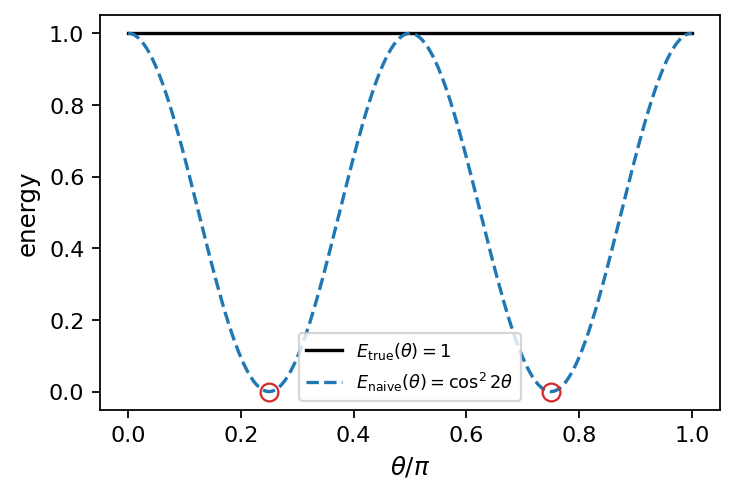

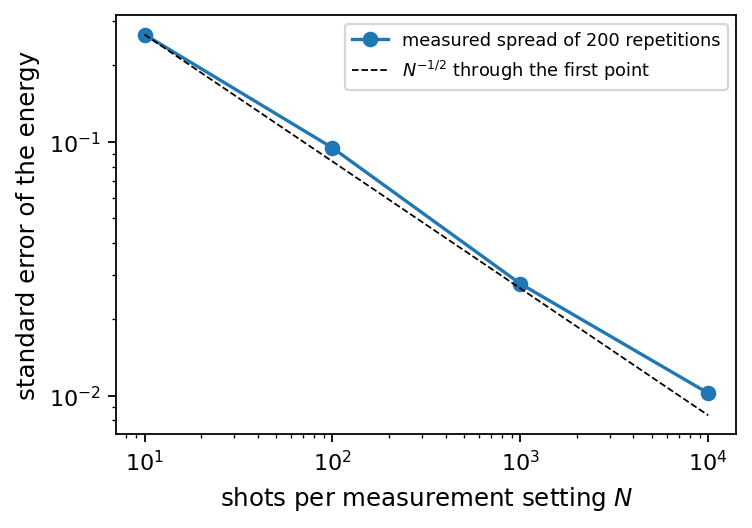

In [4]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter7/measurement.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter7').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== E(theta_k) = A + B cos(theta_k) + C sin(theta_k) for an R_y rotation (Eq. 7.trigpoly)
  A = 0.633345, B = -0.548706, C = 0.468971; largest deviation of the fitted form on 25 other points 8.9e-16
=== two-term rule against finite differences (h = 1e-5): largest difference 1.1e-11

=== A generator with three eigenvalues: G = (Z_0 + Z_1)/2
  eigenvalues of G: [-1.  0.  0.  1.]
  true derivative -1.087126; two-term rule -0.621107; four-term rule (R = 2) -1.087126
  the pair-excitation generators of chapter 4 have the same spectrum, and VQE uses the four-term rule for them

=== Barren plateau: Var[dE/dtheta_1] for the hardware-efficient ansatz with L = n layers (Fig. 7.barren)


  n = 2: variance 1.95e-01, mean -0.017


  n = 3: variance 9.25e-02, mean +0.025


  n = 4: variance 2.87e-02, mean +0.010


  n = 5: variance 1.61e-02, mean +0.018


  n = 6: variance 8.05e-03, mean -0.003


  n = 7: variance 3.80e-03, mean -0.004


  n = 8: variance 1.88e-03, mean +0.003
  slope of log2(variance) against n for n >= 4: -0.99 (an exponential decay 2^(-c n))



=== SPSA against parameter-shift gradient descent on the four-qubit pairing Hamiltonian, HEA with 3 layers (Fig. 7.spsa)


   parameter shift:  2940 energy evaluations, final energy -0.162266 (lowest eigenvalue of the register -0.779164)
              SPSA:  1800 energy evaluations, final energy -0.599486 (lowest eigenvalue of the register -0.779164)

gradient checks passed


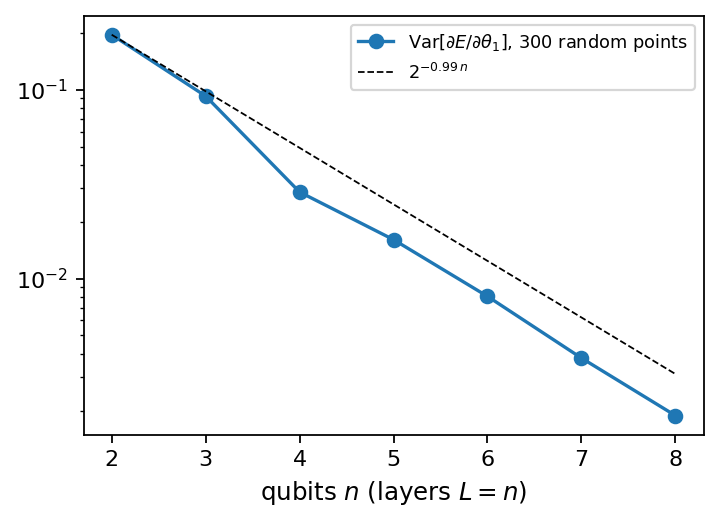

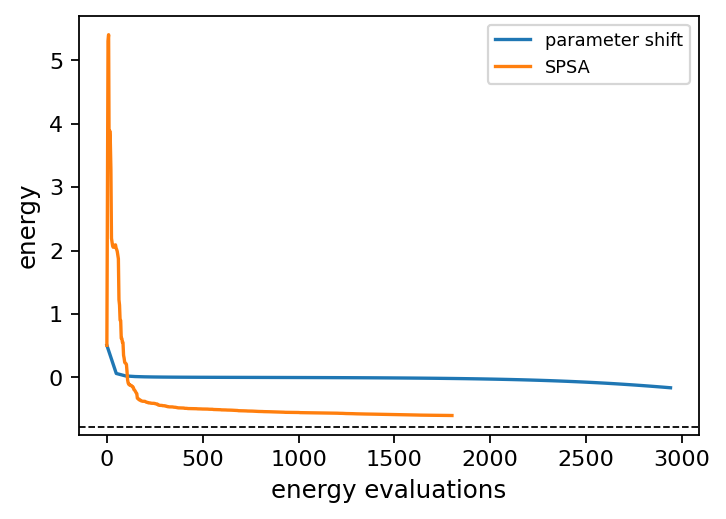

In [5]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter7/gradients.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter7').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== The tapered one-qubit pairing Hamiltonian H = I/2 + Z - X/2 with the R_y ansatz
  VQE -0.6180339887, exact -0.6180339887, error -2.2e-16, angle 2.677945 (tan(theta) = -0.5000, expected -1/2 up to the branch)

=== The two-mode Hamiltonian of Eq. (4.twoqubitH): hardware-efficient ansatz against the single excitation


                          ansatz params      E_VQE   <N>
     hardware-efficient, 1 layer      4   0.000000  0.00
    hardware-efficient, 2 layers      8   0.000000  0.00
     single excitation from |10>      1   0.916905  1.00
  spectrum of the register [0.       0.916905 2.083095 3.5     ]; one-particle ground state 0.916905; the single excitation gives theta = -0.2702

=== The four models with the hardware-efficient ansatz, best of four restarts (Table 7.hea)
           model layers params CNOTs       E_VQE register min  sector E0 |<E0|psi>|^2
   Lipkin, $N=4$      1      8     0   -4.000000    -4.212877  -4.212877       0.9358


   Lipkin, $N=4$      2     16     3   -4.105370    -4.212877  -4.212877       0.9726


   Lipkin, $N=4$      3     24     6   -4.211395    -4.212877  -4.212877       0.9998
  pairing, $L=4$      1      8     0   -0.500000    -0.779164   0.635548       0.0000


  pairing, $L=4$      2     16     3   -0.622012    -0.779164   0.635548       0.0000


...

    Hubbard ring Hamiltonian-variational, 1 layer      2  -1.97671868  -2.10274848  1.3e-01     0.988473


    Hubbard ring Hamiltonian-variational, 2 layers      4  -2.10274848  -2.10274848  1.3e-15     1.000000


    Hubbard ring Hamiltonian-variational, 3 layers      6  -2.10274848  -2.10274848  3.6e-15     1.000000


 Heisenberg ring Hamiltonian-variational, 1 layer      2  -2.00000000  -2.00000000  2.2e-16     1.000000
 Heisenberg ring Hamiltonian-variational, 2 layers      4  -2.00000000  -2.00000000  0.0e+00     1.000000



=== The four models: phase estimation (m = 10, Table 6.qpemodels) against the best variational energies
           model  QPE error  HEA error  physics error physics overlap
   Lipkin, $N=4$    5.9e-03   +1.5e-03       -2.7e-15        1.000000
  pairing, $L=4$    7.3e-03   -1.4e+00       -3.3e-16        1.000000
    Hubbard ring    1.7e-02   +1.0e-01        1.3e-15        1.000000
 Heisenberg ring    1.3e-03   +8.6e-02        0.0e+00        1.000000

model VQE checks passed


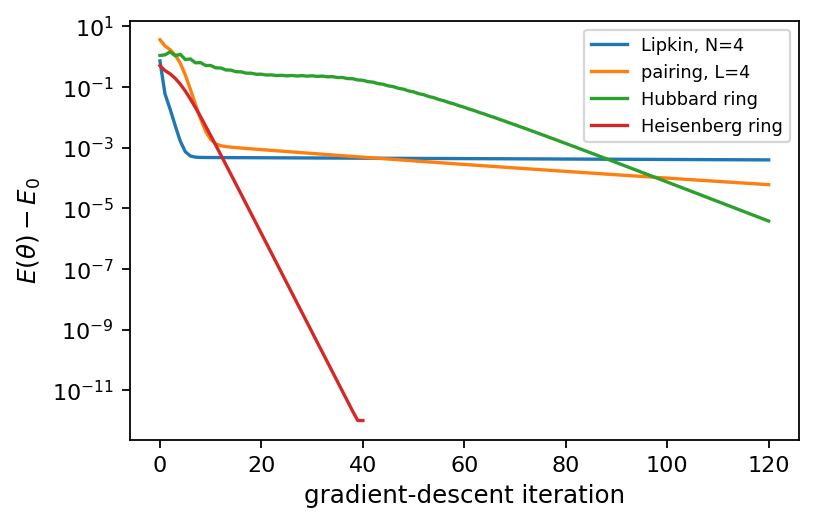

In [6]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter7/vqe_models.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter7').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== Pairing model, L = 4, two pairs: pool of the six pair transfers
    step 1: added          P02 (|grad| = 1.00e+00), E = 0.93844719
    step 2: added          P03 (|grad| = 1.11e+00), E = 0.88724986
    step 3: added          P12 (|grad| = 1.12e+00), E = 0.73887005
    step 4: added          P13 (|grad| = 1.27e+00), E = 0.63698698
    step 5: added          P23 (|grad| = 1.14e-02), E = 0.63554847

=== Lipkin model: the qubit pool and the collective pool
  Lipkin, qubit pool:
    step 1: added         X0Y1 (|grad| = 6.67e-01), E = -4.02758751
    step 2: added         X0Y2 (|grad| = 7.61e-01), E = -4.06438040
    step 3: added         X0Y3 (|grad| = 8.87e-01), E = -4.11604788
    step 4: added         Y1X2 (|grad| = 6.85e-01), E = -4.14536972
    step 5: added         X1Y3 (|grad| = 7.74e-01), E = -4.18379887
    step 6: added         Y2X3 (|grad| = 6.76e-01), E = -4.21279162
    step 7: added         Y0X1 (|grad| = 1.83e-03), E = -4.21287670
  Lipkin, collective pool (2):
    step 1

    step 1: added double 15->16 (|grad| = 9.97e-01), E = -1.15043153
    step 2: added double 27->37 (|grad| = 1.06e+00), E = -1.31383705


    step 3: added double 04->34 (|grad| = 1.06e+00), E = -1.47058160
    step 4: added double 26->27 (|grad| = 9.54e-01), E = -1.59031480


    step 5: added double 05->15 (|grad| = 8.78e-01), E = -1.70285902


    step 6: added double 16->26 (|grad| = 7.84e-01), E = -1.78474359


...

    step 9: added double 14->37 (|grad| = 3.64e-01), E = -2.00587258


    step 10: added double 25->37 (|grad| = 3.80e-01), E = -2.07772333


    step 11: added double 24->27 (|grad| = 2.47e-01), E = -2.08719613


    step 12: added double 07->16 (|grad| = 2.40e-01), E = -2.09135394

=== Summary (Table 7.adapt)
                  model / pool  pool  ops      E_ADAPT     error |<E0|psi>|^2
   pairing, six pair transfers     6    5   0.63554847  -3.3e-16     1.000000
            Lipkin, qubit pool    28    7  -4.21287670   9.8e-15     1.000000
   Lipkin, collective pool (2)     2    1  -4.21240735   4.7e-04     0.999942
   Lipkin, collective pool (3)     3    2  -4.21287670  -8.9e-16     1.000000
     Heisenberg, from singlets     8    1  -2.00000000  -4.4e-16     1.000000
         Heisenberg, from Neel     8    3  -2.00000000   4.4e-16     1.000000
       Hubbard, fermionic pool   162   12  -2.09135394   1.1e-02     0.997668



ADAPT-VQE checks passed


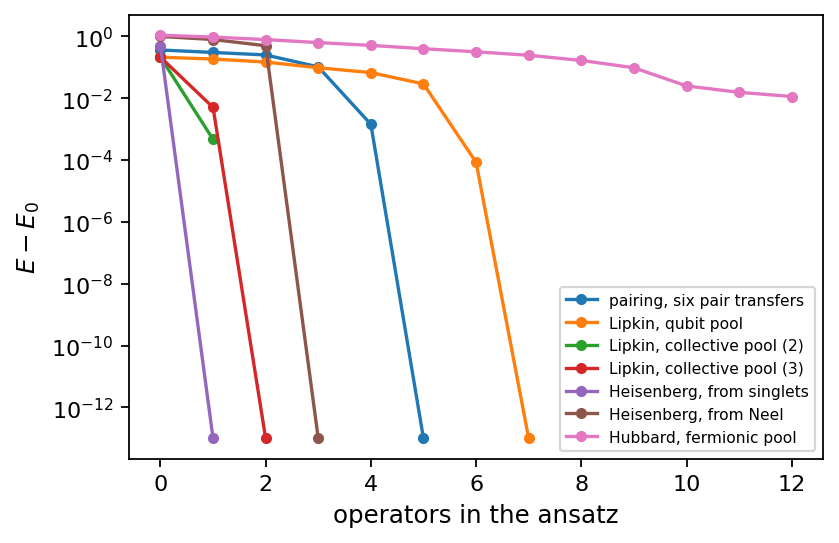

In [7]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter7/adapt_vqe.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter7').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


=== QUBO x^T Q x with Q = [[1, -2], [-2, 1]] -> Ising (Table 7.qubo)
  J_01 = -1.0, h = {0: np.float64(0.5), 1: np.float64(0.5)}, constant = 0.0; H_C = {'ZZ': np.float64(-1.0), 'ZI': np.float64(0.5), 'IZ': np.float64(0.5)}
  x = (0, 0): x^T Q x = +0.0, H_C(z) + const = +0.0
  x = (0, 1): x^T Q x = +1.0, H_C(z) + const = +1.0
  x = (1, 0): x^T Q x = +1.0, H_C(z) + const = +1.0
  x = (1, 1): x^T Q x = -2.0, H_C(z) + const = -2.0

=== One edge, p = 1: <Z_0 Z_1> = -sin(4 beta) sin(gamma)
  largest deviation from the formula over a 13 x 11 grid: 6.7e-16
  optimum F = 1.000000 at gamma = 1.5708, beta = 1.9635 (the cut of one edge is 1: the single edge is solved exactly at p = 1)

=== QAOA for MaxCut (Table 7.qaoa)
                   graph C_max  p      F_p   ratio  P(optimal cut)                    gamma, beta
              ring $C_4$     4  1   3.0000  0.7500          0.5312                 (2.356, 2.749)


              ring $C_4$     4  2   4.0000  1.0000          1.0000   (1.571, 2.356, 2.749, 0.785)


              ring $C_4$     4  3   4.0000  1.0000          1.0000 (1.572, 6.222, 3.988, 0.350, 1.614, 0.785)
 prism graph, 6 vertices     7  1   5.9392  0.8485          0.4008                 (2.571, 0.348)


 prism graph, 6 vertices     7  2   6.6029  0.9433          0.7209   (0.502, 0.917, 0.478, 1.857)


 prism graph, 6 vertices     7  3   6.8780  0.9826          0.9233 (2.733, 2.284, 2.097, 2.077, 1.228, 0.169)
  ring, p = 1: largest deviation from F_1 = 2 + sin(4 beta) sin(2 gamma): 4.8e-15


  ring, p = 1: largest F on the grid 2.9945 (optimiser 3.0000)



QAOA checks passed


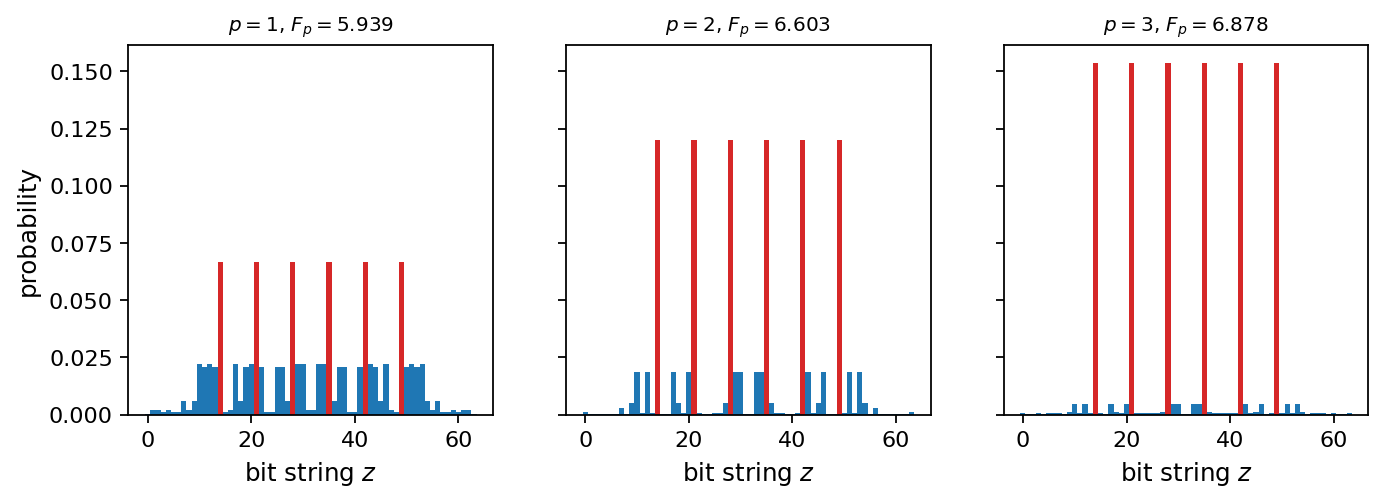

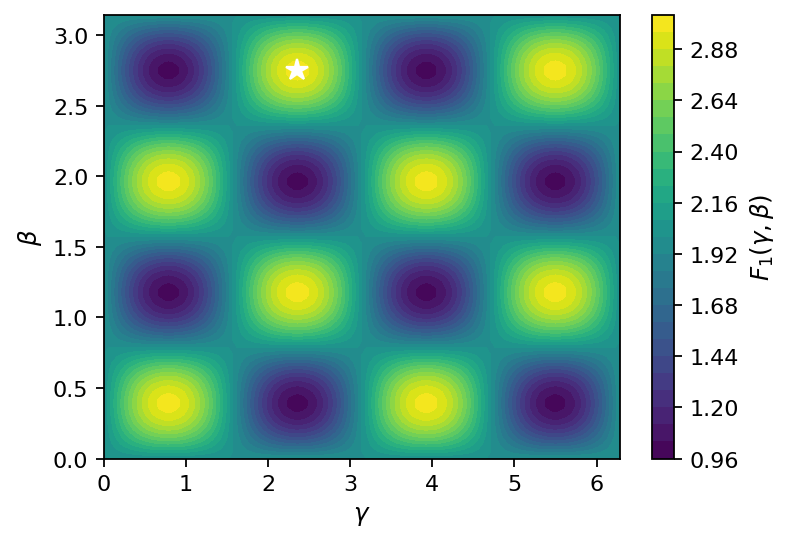

In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter7/qaoa.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter7').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
